In [2]:
import matplotlib.pyplot as plt
import matplotlib as mpl
# from matplotlib import ticker
# import matplotlib.patches as patches
import numpy as np
import pandas as pd
import seaborn as sns
import bioframe as bf
import bbi
import cooler
import cooltools
from coolpuppy import coolpup
from cooltools.sandbox.expected_smoothing import log_smooth
from pybedtools import BedTool as pbt
import networkx as nx
# from pyvis.network import Network
from scipy.stats import mannwhitneyu, wilcoxon
from sklearn.linear_model import LinearRegression
from joblib import Memory
import pycircos
import collections
# import utils




In [3]:
# Add cache functionality to some functions
cachedir = 'cache'
memory = Memory(cachedir, verbose=0)

expected_cis_cache = memory.cache(cooltools.expected_cis, ignore=['nproc'])
expected_trans_cache = memory.cache(cooltools.expected_trans, ignore=['nproc'])
pileup_cache = memory.cache(coolpup.pileup, ignore=['nproc'])


# Matplotlib bsettings
mpl.rc('lines', linewidth=0.4)
mpl.rc('font', family='Helvetica', size=8)
mpl.rc('axes', labelsize=8, titlesize=8, linewidth=0.4)
mpl.rc('legend', fontsize=8)
mpl.rc('xtick', labelsize=6)
mpl.rc('xtick.major', width=0.4, size=2)
mpl.rc('xtick.minor', width=0.4, size=1)
mpl.rc('ytick', labelsize=6)
mpl.rc('ytick.major', width=0.4, size=2)
mpl.rc('ytick.minor', width=0.4, size=1)

colors = {'NeuN+': sns.color_palette()[4], 
          'NeuN-': sns.color_palette()[1]}

In [14]:
clr_path = {
        "Pletenev_NeuNplus": '/tank/projects/mm_brain/2024_05_03/Ring1B_and_Lag_HiC/distiller_run_pilot_Neulag/results/coolers_library/Pletenev2024_NeuNplus.sampled_mm.mcool',
        "Cortical_Neu_Lagarkova": '/tank/projects/mm_brain/2024_05_03/Ring1B_and_Lag_HiC/distiller_run_Neulag2/results/coolers_library/Neu_culture_Lag_mrg_all.hg38_drop_diag.1kb.mcool'
    # "Lindsly_B_cell_G1": '/tank/projects/kmorozov/open_source/hi-c/GSE159813_Bcell/GSE159813_B_cell_G1_phase.hg38.mapq_30.1000.mcool',
    # "Lindsly_B_cell_G2": '/tank/projects/kmorozov/open_source/hi-c/GSE159813_Bcell/GSE159813_B_cell_G2_phase.hg38.mapq_30.1000.mcool',
    # "Lindsly_B_cell_S": '/tank/projects/kmorozov/open_source/hi-c/GSE159813_Bcell/GSE159813_B_cell_S_phase.hg38.mapq_30.1000.mcool',
    # "Feng_heart_DCM_1": '/tank/projects/kmorozov/open_source/hi-c/GSE165303_human_heart/GSE165303_heart_DCM_1.hg38.mapq_30.1000.mcool',
    # "Feng_heart_DCM_2": '/tank/projects/kmorozov/open_source/hi-c/GSE165303_human_heart/GSE165303_heart_DCM_2.hg38.mapq_30.1000.mcool',
    # "Feng_heart_NF_1": '/tank/projects/kmorozov/open_source/hi-c/GSE165303_human_heart/GSE165303_heart_NF_1.hg38.mapq_30.1000.mcool',
    # "Feng_heart_NF_2": '/tank/projects/kmorozov/open_source/hi-c/GSE165303_human_heart/GSE165303_heart_NF_2.hg38.mapq_30.1000.mcool',
    # "Bunting_B_cells_GCB_1": '/tank/projects/kmorozov/open_source/hi-c/GSE84022_B_cell/GSE84022_B_cells_GCB_1.hg38.mapq_30.1000.mcool',
    # "Bunting_B_cells_GCB_2": '/tank/projects/kmorozov/open_source/hi-c/GSE84022_B_cell/GSE84022_B_cells_GCB_2.hg38.mapq_30.1000.mcool',
    # "Bunting_B_cells_NB_1": '/tank/projects/kmorozov/open_source/hi-c/GSE84022_B_cell/GSE84022_B_cells_NB_1.hg38.mapq_30.1000.mcool',
    # "Bunting_B_cells_NB_2": '/tank/projects/kmorozov/open_source/hi-c/GSE84022_B_cell/GSE84022_B_cells_NB_2.hg38.mapq_30.1000.mcool',
    # "Sungalee_B_cells_GCB_1": '/tank/projects/kmorozov/open_source/hi-c/GSE168470_B_cell/GSE168470_B_cells_GCB_1.hg38.mapq_30.1000.mcool',
    # "Sungalee_B_cells_GCB_2": '/tank/projects/kmorozov/open_source/hi-c/GSE168470_B_cell/GSE168470_B_cells_GCB_2.hg38.mapq_30.1000.mcool'
    # "PE_Neuron_rep2b": '/tank/projects/kmorozov/open_source/hi-c/iPSC_Hi-C/Neuron2b.hg38.mapq_30.1000.mcool',
    # "PE_NPC_rep1": '/tank/projects/kmorozov/open_source/hi-c/iPSC_Hi-C/NPC1.hg38.mapq_30.1000.mcool',
    # "PE_NPC_rep2a": '/tank/projects/kmorozov/open_source/hi-c/iPSC_Hi-C/NPC2a.hg38.mapq_30.1000.mcool',
    # "PE_NPC_rep2b": '/tank/projects/kmorozov/open_source/hi-c/iPSC_Hi-C/NPC2b.hg38.mapq_30.1000.mcool',
    # "PE_Glia_rep1": '/tank/projects/kmorozov/open_source/hi-c/iPSC_Hi-C/Glia1.hg38.mapq_30.1000.mcool',
    # "PE_Glia_rep2a": '/tank/projects/kmorozov/open_source/hi-c/iPSC_Hi-C/Glia2a.hg38.mapq_30.1000.mcool',
    # "PE_Glia_rep2b": '/tank/projects/kmorozov/open_source/hi-c/iPSC_Hi-C/Glia2b.hg38.mapq_30.1000.mcool',
    # "Lu2020_Neurons": "/tank/projects/schizophrenia_2021/hi-c/hNeurons_and_NPC/HiC_merged_hNeurons.hg38.mapq_30.1000.mcool",
    # # "Lu2020_NPC": "/tank/projects/schizophrenia_2021/hi-c/hNeurons_and_NPC/HiC_merged_NPC.hg38.mapq_30.1000.cool",
    # 'our_NeuN+': "NeuNplus.our.mcool",
    # 'our_NeuN-': "NeuNminus.our.mcool",
    # "Choi2020_iPSC_rep1": "/tank/projects/kmorozov/open_source/hi-c/GSE158382/SRR12694368.hg38.mapq_30.1000.mcool",
    # "Choi2020_iPSC_rep2": "/tank/projects/kmorozov/open_source/hi-c/GSE158382/SRR12694369.hg38.mapq_30.1000.mcool",
    # "Choi2020_NPC_rep1": "/tank/projects/kmorozov/open_source/hi-c/GSE158382/SRR12694370.hg38.mapq_30.1000.mcool",
    # "Choi2020_NPC_rep1": "/tank/projects/kmorozov/open_source/hi-c/GSE158382/SRR12694371.hg38.mapq_30.1000.mcool",   
    # "Rahman_iPSC_neurons": "/tank/projects/schizophrenia_2021/data/rahman2023/CRISPRi_Scrambled_A_DpnII-HinfI.mcool"
}

cts = list(clr_path.keys()) # cell types

## Plot: average neuronal dot

In [15]:
# Load hi-c matrices
# res = 10_000
res = 10_000

clrs = {ct: cooler.Cooler(clr_path[ct] + f'::resolutions/{res}') 
        for ct in cts}

In [16]:
# Load peaks and merge
hand_anch = pd.read_excel("/tank/projects/schizophrenia_2021/results/2024.01.10/Supp.Table_polycomb_dot_anchors.xlsx", na_values='-')

hand_anch.loc[:, 'mid_start'] = (hand_anch['start'] + hand_anch['end']) / 2 \
    - ((hand_anch['start'] + hand_anch['end']) / 2) % res
hand_anch.loc[:, 'mid_end'] = hand_anch['mid_start'] + res
hand_anch.loc[:, 'mid_start'] = hand_anch.loc[:, 'mid_start'].astype(int)
hand_anch.loc[:, 'mid_end'] = hand_anch.loc[:, 'mid_end'].astype(int)
    
hand_anch.head()

,chrom,start,end,genes,mid_start,mid_end
0,chr1,18630000,18640000,PAX7,18630000.0,18640000.0
1,chr1,24930000,24940000,RUNX3,24930000.0,24940000.0
2,chr1,44410000,44420000,RNF220,44410000.0,44420000.0
3,chr1,46480000,46490000,DMBX1,46480000.0,46490000.0
4,chr1,47230000,47240000,"TAL1,AL135960.1",47230000.0,47240000.0


In [17]:
# CIS obs/exp
cvd_10 = {}

for ct in cts:
    print(ct)
    cvd_10[ct] = expected_cis_cache(
        clrs[ct],
        smooth=False,
        nproc=10
    )

Pletenev_NeuNplus
Cortical_Neu_Lagarkova


In [18]:
# TRANS obs/exp
trans_cvd_10 = {}

for ct in cts:
    print(ct)
    trans_cvd_10[ct] = expected_trans_cache(
        clrs[ct],
#         view_df=hg38_chromsizes_view,
        nproc=10
    )

Pletenev_NeuNplus
Cortical_Neu_Lagarkova


In [19]:
# Set the resolution (in bp)
resolution = 1000
suffix = f"::resolutions/{resolution}"

# Loop through each file and count the number of contacts
for name, path in clr_path.items():
    try:
        clr = cooler.Cooler(path + suffix)
        num_contacts = clr.info['nnz']  # Number of non-zero contacts
        print(f"{name}: {num_contacts:,} contacts")
    except Exception as e:
        print(f"{name}: ERROR - {e}")

Pletenev_NeuNplus: 97,607,431 contacts
Cortical_Neu_Lagarkova: 325,567,469 contacts


In [20]:
# Split by distance
nproc=20
pup_hand = {ct: {} for ct in cts}
# pup_hand['NeuN+'] = {}
# pup_hand['NeuN-'] = {}

for ct in cts:
    print(ct)
    pup_hand[ct]['short'] = pileup_cache(
        clrs[ct], 
        hand_anch,
        expected_df=cvd_10[ct],
        flank=150000,
        mindist=3*res,
        maxdist=int(3e6),
        nproc=nproc
    );
    pup_hand[ct]['long'] = pileup_cache(
        clrs[ct], 
        hand_anch,
        expected_df=cvd_10[ct],
        flank=150000,
        mindist=int(3e6),
        nproc=nproc
    );
    pup_hand[ct]['trans'] = pileup_cache(
        clrs[ct], 
        hand_anch,
        expected_df=trans_cvd_10[ct],
        flank=150000,
        trans=True,
        nproc=nproc
    );

Pletenev_NeuNplus
Cortical_Neu_Lagarkova


In [21]:
# Save pup_dong
# for hic_ct in ["NeuN+", "NeuN-"]:
#     for k27_ct in ['NeuN+', 'NeuN-']:
#         for grp in ['short', 'long', 'trans']:
#             np.save(f"pup_dong.hic-{hic_ct}.k27-{k27_ct}.grp-{grp}.npy", pup_dong[hic_ct][k27_ct][grp]['data'][0])

In [22]:
# # Read pup_dong
# for hic_ct in ["NeuN+", "NeuN-"]:
#     for k27_ct in ['NeuN+', 'NeuN-']:
#         for grp in ['short', 'long', 'trans']:
#             pup_dong[hic_ct][k27_ct][grp] = np.load(f"pup_dong.hic-{hic_ct}.k27-{k27_ct}.grp-{grp}.npy", 
#                                                     allow_pickle=True)

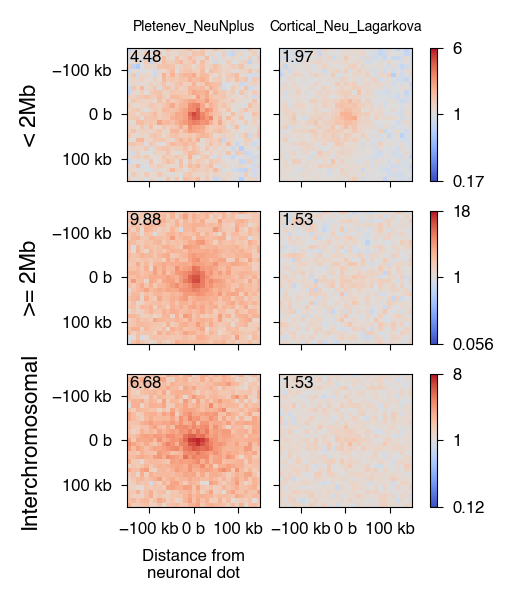

In [23]:
# Plot data for each ct separately
from matplotlib.colors import LogNorm
from coolpuppy.lib.numutils import get_enrichment
from matplotlib import ticker
from matplotlib.ticker import EngFormatter
bp_formatter = EngFormatter('b')

# Method 1: Modifying individual parameters

# plt.rcParams['axes.labelsize'] = 14      # Font size for x and y labels
# plt.rcParams['xtick.labelsize'] = 12    # Font size for x-axis tick labels
# plt.rcParams['ytick.labelsize'] = 12    # Font size for y-axis tick labels
# plt.rcParams['legend.fontsize'] = 10     # Font size for legend entries
# plt.rcParams['font.size'] = 12          # General font size for all text elements


def format_ticks(ax, x=True, y=True, rotate=True):
    if y:
        ax.yaxis.set_major_formatter(bp_formatter)
        ax.yaxis.set_major_locator(ticker.MultipleLocator(1e5))
    if x:
        ax.xaxis.set_major_formatter(bp_formatter)
        ax.xaxis.set_major_locator(ticker.MultipleLocator(1e5))
        ax.xaxis.tick_bottom()
        
        
nrows, ncols = 3, len(cts)
wr = [1]*ncols
wr.append(0.05)
fig, axs = plt.subplots(nrows, ncols+1, dpi=200, figsize=(ncols, nrows),
                        gridspec_kw={'width_ratios': wr})

vmax = {'short': 6, 'long': 18, 'trans': 8}
vmin = {k: 1/val for k, val in vmax.items()}
pup_grps = ['short', 'long', 'trans']

for i, pup in enumerate(pup_grps):
    for j, ct in enumerate(cts):
        arr = pup_hand[ct][pup]['data'][0]
        im = axs[i, j].imshow(
            arr, 
            cmap='coolwarm',
            norm=LogNorm(vmax=vmax[pup], vmin=vmin[pup]),
            extent=(-150000, 150000, 150000, -150000)
        )
        
        # Enrichment
        en = get_enrichment(arr, 0)
        axs[i, j].text(0.02, 0.98, round(en, 2), va='top', 
                       transform=axs[i, j].transAxes, fontsize=6)
        
        format_ticks(axs[i, j])
    
    # Colorbar
    plt.colorbar(im, cax=axs[i, ncols], ticks=[vmin[pup], 1, vmax[pup]], 
                 format=ticker.FuncFormatter(lambda x, pos: f"{x:.2g}"))
    axs[i, ncols].set_box_aspect(20)
    axs[i, ncols].minorticks_off()

# Ticks
for i in range(3):
    for j in range(1, ncols):
        axs[i, j].yaxis.set_ticklabels([])

# for i, j in [[0, 0], [0, 1], [1, 0], [1, 1]]:
#     axs[i, j].xaxis.set_ticklabels([])

for i in range(nrows-1):
    for j in range(ncols):
       axs[i, j].xaxis.set_ticklabels([]) 
    
# Labels
for i, ct in enumerate(cts):
    axs[0, i].set_title(ct, size=5)
# axs[0, 1].set_title(cts[1])
axs[0, 0].set_ylabel('< 2Mb', size=8)
axs[1, 0].set_ylabel('>= 2Mb', size=8)
axs[2, 0].set_ylabel('Interchromosomal', size=8)

axs[2, 0].set_xlabel('Distance from\nneuronal dot', size=6)
# axs[2, 1].set_xlabel('Distance from\nH3K27me3 peak')

# plt.tight_layout()

# plt.savefig('coolpup.hand.our_and_Hu2021_merged.pdf', bbox_inches='tight')
# plt.savefig('coolpup.hand.our.pdf', bbox_inches='tight')
# plt.savefig('coolpup.hand.Hu2021.pdf', bbox_inches='tight')
# plt.savefig('coolpup.hand.Tian2023.EN_IN.MTG.pdf', bbox_inches='tight')
plt.savefig('poster_Lagarkova.pdf', bbox_inches='tight')

### All_B_Cells

In [24]:
clr_path = {
    "Cortical_Neu_Lagarkova": '/tank/projects/mm_brain/2024_05_03/Ring1B_and_Lag_HiC/distiller_run_Neulag2/results/coolers_library/Neu_culture_Lag_mrg_all.hg38_drop_diag.1kb.mcool',
    "Pletenev_NeuNplus": '/tank/projects/mm_brain/2024_05_03/Ring1B_and_Lag_HiC/distiller_run_pilot_Neulag/results/coolers_library/Pletenev2024_NeuNplus.sampled_mm.mcool',
    "Lindsly_B_cell_G1": '/tank/projects/kmorozov/open_source/hi-c/GSE159813_Bcell/GSE159813_B_cell_G1_phase.hg38.mapq_30.1000.mcool',
    "Lindsly_B_cell_G2": '/tank/projects/kmorozov/open_source/hi-c/GSE159813_Bcell/GSE159813_B_cell_G2_phase.hg38.mapq_30.1000.mcool',
    "Lindsly_B_cell_S": '/tank/projects/kmorozov/open_source/hi-c/GSE159813_Bcell/GSE159813_B_cell_S_phase.hg38.mapq_30.1000.mcool',
    # "Feng_heart_DCM_1": '/tank/projects/kmorozov/open_source/hi-c/GSE165303_human_heart/GSE165303_heart_DCM_1.hg38.mapq_30.1000.mcool',
    # "Feng_heart_DCM_2": '/tank/projects/kmorozov/open_source/hi-c/GSE165303_human_heart/GSE165303_heart_DCM_2.hg38.mapq_30.1000.mcool',
    # "Feng_heart_NF_1": '/tank/projects/kmorozov/open_source/hi-c/GSE165303_human_heart/GSE165303_heart_NF_1.hg38.mapq_30.1000.mcool',
    # "Feng_heart_NF_2": '/tank/projects/kmorozov/open_source/hi-c/GSE165303_human_heart/GSE165303_heart_NF_2.hg38.mapq_30.1000.mcool',
    "Bunting_B_cells_GCB_1": '/tank/projects/kmorozov/open_source/hi-c/GSE84022_B_cell/GSE84022_B_cells_GCB_1.hg38.mapq_30.1000.mcool',
    "Bunting_B_cells_GCB_2": '/tank/projects/kmorozov/open_source/hi-c/GSE84022_B_cell/GSE84022_B_cells_GCB_2.hg38.mapq_30.1000.mcool',
    "Bunting_B_cells_NB_1": '/tank/projects/kmorozov/open_source/hi-c/GSE84022_B_cell/GSE84022_B_cells_NB_1.hg38.mapq_30.1000.mcool',
    "Bunting_B_cells_NB_2": '/tank/projects/kmorozov/open_source/hi-c/GSE84022_B_cell/GSE84022_B_cells_NB_2.hg38.mapq_30.1000.mcool',
    "Sungalee_B_cells_GCB_1": '/tank/projects/kmorozov/open_source/hi-c/GSE168470_B_cell/GSE168470_B_cells_GCB_1.hg38.mapq_30.1000.mcool',
    "Sungalee_B_cells_GCB_2": '/tank/projects/kmorozov/open_source/hi-c/GSE168470_B_cell/GSE168470_B_cells_GCB_2.hg38.mapq_30.1000.mcool',
    # "Anya_DS_pancr_cells_acinar": '/tank/projects/cell_hic_compare/mcool_merged/merged/HiC_acinar.hg38.mapq_30.1000.mcool',
    # "Anya_DS_pancr_cells_alpha": "/tank/projects/cell_hic_compare/mcool_merged/merged/HiC_alpha.hg38.mapq_30.1000.mcool",
    # "Anya_DS_pancr_cells_beta": "/tank/projects/cell_hic_compare/mcool_merged/merged/HiC_beta.hg38.mapq_30.1000.mcool",
    "VilarrasaBlasi_B_cells_MBC": "/tank/projects/cell_hic_compare/mcool_merged/merged/MBC.hg38.mapq_30.1000.mcool",
    "VilarrasaBlasi_B_cells_NBC": "/tank/projects/cell_hic_compare/mcool_merged/merged/NBC.hg38.mapq_30.1000.mcool",
    "VilarrasaBlasi_B_cells_PC": "/tank/projects/cell_hic_compare/mcool_merged/merged/PC.hg38.mapq_30.1000.mcool",
    # Bediaga_ dataset - B cells
    "Bediaga_Mature_B_cells_1": '/tank/projects/kmorozov/open_source/hi-c/GSE126117_act_cd4_8/GSE126117_B_cells_1.hg38.mapq_30.1000.mcool',
    "Bediaga_Mature_B_cells_2": '/tank/projects/kmorozov/open_source/hi-c/GSE126117_act_cd4_8/GSE126117_B_cells_2.hg38.mapq_30.1000.mcool',

    # # Yang_ dataset - GSE138767 CD4+ T cell activation time course
    # "Yang_CD4_T_cells_stim_1hr_1": '/tank/projects/kmorozov/open_source/hi-c/GSE138767_cd4_activation/GSE138767_primary_CD4_T_cells_stim_1hr_1.hg38.mapq_30.1000.mcool',
    # "Yang_CD4_T_cells_stim_1hr_2": '/tank/projects/kmorozov/open_source/hi-c/GSE138767_cd4_activation/GSE138767_primary_CD4_T_cells_stim_1hr_2.hg38.mapq_30.1000.mcool',
    # "Yang_CD4_T_cells_stim_4hr_1": '/tank/projects/kmorozov/open_source/hi-c/GSE138767_cd4_activation/GSE138767_primary_CD4_T_cells_stim_4hr_1.hg38.mapq_30.1000.mcool',
    # "Yang_CD4_T_cells_stim_4hr_2": '/tank/projects/kmorozov/open_source/hi-c/GSE138767_cd4_activation/GSE138767_primary_CD4_T_cells_stim_4hr_2.hg38.mapq_30.1000.mcool',
    # "Yang_CD4_T_cells_stim_20min_1": '/tank/projects/kmorozov/open_source/hi-c/GSE138767_cd4_activation/GSE138767_primary_CD4_T_cells_stim_20min_1.hg38.mapq_30.1000.mcool',
    # "Yang_CD4_T_cells_stim_20min_2": '/tank/projects/kmorozov/open_source/hi-c/GSE138767_cd4_activation/GSE138767_primary_CD4_T_cells_stim_20min_2.hg38.mapq_30.1000.mcool',
    # "Yang_CD4_T_cells_stim_24hr_1": '/tank/projects/kmorozov/open_source/hi-c/GSE138767_cd4_activation/GSE138767_primary_CD4_T_cells_stim_24hr_1.hg38.mapq_30.1000.mcool',
    # "Yang_CD4_T_cells_unstim_1": '/tank/projects/kmorozov/open_source/hi-c/GSE138767_cd4_activation/GSE138767_primary_CD4_T_cells_unstim_1.hg38.mapq_30.1000.mcool',
    # "Yang_CD4_T_cells_unstim_2": '/tank/projects/kmorozov/open_source/hi-c/GSE138767_cd4_activation/GSE138767_primary_CD4_T_cells_unstim_2.hg38.mapq_30.1000.mcool',
    
    # # Bediaga_ dataset - T cells
    # "Bediaga_activated_CD4_T_cells_1": '/tank/projects/kmorozov/open_source/hi-c/GSE126117_act_cd4_8/GSE126117_activated_CD4_T_cells_1.hg38.mapq_30.1000.mcool',
    # "Bediaga_activated_CD4_T_cells_2": '/tank/projects/kmorozov/open_source/hi-c/GSE126117_act_cd4_8/GSE126117_activated_CD4_T_cells_2.hg38.mapq_30.1000.mcool',
    # "Bediaga_activated_CD8_T_cells_1": '/tank/projects/kmorozov/open_source/hi-c/GSE126117_act_cd4_8/GSE126117_activated_CD8_T_cells_1.hg38.mapq_30.1000.mcool',
    # "Bediaga_activated_CD8_T_cells_2": '/tank/projects/kmorozov/open_source/hi-c/GSE126117_act_cd4_8/GSE126117_activated_CD8_T_cells_2.hg38.mapq_30.1000.mcool',
    # "Bediaga_naive_CD4_T_cells_1": '/tank/projects/kmorozov/open_source/hi-c/GSE126117_act_cd4_8/GSE126117_naive_CD4_T_cells_1.hg38.mapq_30.1000.mcool',
    # "Bediaga_naive_CD4_T_cells_2": '/tank/projects/kmorozov/open_source/hi-c/GSE126117_act_cd4_8/GSE126117_naive_CD4_T_cells_2.hg38.mapq_30.1000.mcool',
    # "Bediaga_naive_CD8_T_cells_1": '/tank/projects/kmorozov/open_source/hi-c/GSE126117_act_cd4_8/GSE126117_naive_CD8_T_cells_1.hg38.mapq_30.1000.mcool',
    # "Bediaga_naive_CD8_T_cells_2": '/tank/projects/kmorozov/open_source/hi-c/GSE126117_act_cd4_8/GSE126117_naive_CD8_T_cells_2.hg38.mapq_30.1000.mcool'

    # "PE_Neuron_rep2b": '/tank/projects/kmorozov/open_source/hi-c/iPSC_Hi-C/Neuron2b.hg38.mapq_30.1000.mcool',
    # "PE_NPC_rep1": '/tank/projects/kmorozov/open_source/hi-c/iPSC_Hi-C/NPC1.hg38.mapq_30.1000.mcool',
    # "PE_NPC_rep2a": '/tank/projects/kmorozov/open_source/hi-c/iPSC_Hi-C/NPC2a.hg38.mapq_30.1000.mcool',
    # "PE_NPC_rep2b": '/tank/projects/kmorozov/open_source/hi-c/iPSC_Hi-C/NPC2b.hg38.mapq_30.1000.mcool',
    # "PE_Glia_rep1": '/tank/projects/kmorozov/open_source/hi-c/iPSC_Hi-C/Glia1.hg38.mapq_30.1000.mcool',
    # "PE_Glia_rep2a": '/tank/projects/kmorozov/open_source/hi-c/iPSC_Hi-C/Glia2a.hg38.mapq_30.1000.mcool',
    # "PE_Glia_rep2b": '/tank/projects/kmorozov/open_source/hi-c/iPSC_Hi-C/Glia2b.hg38.mapq_30.1000.mcool',
    # "Lu2020_Neurons": "/tank/projects/schizophrenia_2021/hi-c/hNeurons_and_NPC/HiC_merged_hNeurons.hg38.mapq_30.1000.mcool",
    # # "Lu2020_NPC": "/tank/projects/schizophrenia_2021/hi-c/hNeurons_and_NPC/HiC_merged_NPC.hg38.mapq_30.1000.cool",
    # 'our_NeuN+': "NeuNplus.our.mcool",
    # 'our_NeuN-': "NeuNminus.our.mcool",
    # "Choi2020_iPSC_rep1": "/tank/projects/kmorozov/open_source/hi-c/GSE158382/SRR12694368.hg38.mapq_30.1000.mcool",
    # "Choi2020_iPSC_rep2": "/tank/projects/kmorozov/open_source/hi-c/GSE158382/SRR12694369.hg38.mapq_30.1000.mcool",
    # "Choi2020_NPC_rep1": "/tank/projects/kmorozov/open_source/hi-c/GSE158382/SRR12694370.hg38.mapq_30.1000.mcool",
    # "Choi2020_NPC_rep1": "/tank/projects/kmorozov/open_source/hi-c/GSE158382/SRR12694371.hg38.mapq_30.1000.mcool",   
    # "Rahman_iPSC_neurons": "/tank/projects/schizophrenia_2021/data/rahman2023/CRISPRi_Scrambled_A_DpnII-HinfI.mcool"
}

cts = list(clr_path.keys()) # cell types

In [25]:
# Load hi-c matrices
# res = 10_000
res = 10_000

clrs = {ct: cooler.Cooler(clr_path[ct] + f'::resolutions/{res}') 
        for ct in cts}

In [26]:
# Set the resolution (in bp)
resolution = 1000
suffix = f"::resolutions/{resolution}"

# Loop through each file and count the number of contacts
for name, path in clr_path.items():
    try:
        clr = cooler.Cooler(path + suffix)
        num_contacts = clr.info['nnz']  # Number of non-zero contacts
        print(f"{name}: {num_contacts:,} contacts")
    except Exception as e:
        print(f"{name}: ERROR - {e}")

Cortical_Neu_Lagarkova: 325,567,469 contacts
Pletenev_NeuNplus: 97,607,431 contacts
Lindsly_B_cell_G1: 267,289,464 contacts
Lindsly_B_cell_G2: 317,520,871 contacts
Lindsly_B_cell_S: 284,228,914 contacts
Bunting_B_cells_GCB_1: 62,844,618 contacts
Bunting_B_cells_GCB_2: 62,844,618 contacts
Bunting_B_cells_NB_1: 83,623,440 contacts
Bunting_B_cells_NB_2: 104,697,453 contacts
Sungalee_B_cells_GCB_1: 16,325,149 contacts
Sungalee_B_cells_GCB_2: 52,755,756 contacts
VilarrasaBlasi_B_cells_MBC: 284,486,098 contacts
VilarrasaBlasi_B_cells_NBC: 258,994,406 contacts
VilarrasaBlasi_B_cells_PC: 217,906,226 contacts
Bediaga_Mature_B_cells_1: 171,133,638 contacts
Bediaga_Mature_B_cells_2: 170,130,859 contacts


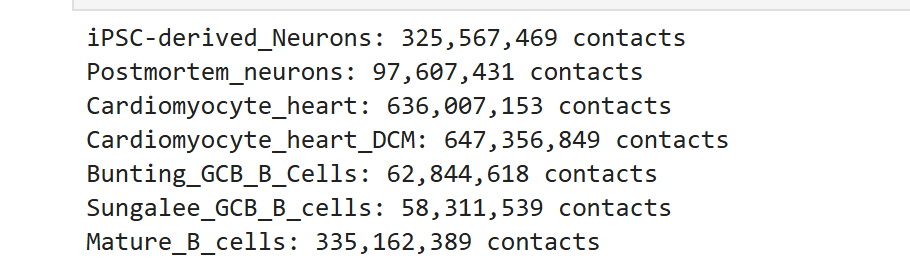

In [27]:
# Load peaks and merge
hand_anch = pd.read_excel("/tank/projects/schizophrenia_2021/results/2024.01.10/Supp.Table_polycomb_dot_anchors.xlsx", na_values='-')

hand_anch.loc[:, 'mid_start'] = (hand_anch['start'] + hand_anch['end']) / 2 \
    - ((hand_anch['start'] + hand_anch['end']) / 2) % res
hand_anch.loc[:, 'mid_end'] = hand_anch['mid_start'] + res
hand_anch.loc[:, 'mid_start'] = hand_anch.loc[:, 'mid_start'].astype(int)
hand_anch.loc[:, 'mid_end'] = hand_anch.loc[:, 'mid_end'].astype(int)
    
hand_anch.head()

,chrom,start,end,genes,mid_start,mid_end
0,chr1,18630000,18640000,PAX7,18630000.0,18640000.0
1,chr1,24930000,24940000,RUNX3,24930000.0,24940000.0
2,chr1,44410000,44420000,RNF220,44410000.0,44420000.0
3,chr1,46480000,46490000,DMBX1,46480000.0,46490000.0
4,chr1,47230000,47240000,"TAL1,AL135960.1",47230000.0,47240000.0


In [28]:
# CIS obs/exp
cvd_10 = {}

for ct in cts:
    print(ct)
    cvd_10[ct] = expected_cis_cache(
        clrs[ct],
        smooth=False,
        nproc=10
    )

Cortical_Neu_Lagarkova
Pletenev_NeuNplus
Lindsly_B_cell_G1
Lindsly_B_cell_G2
Lindsly_B_cell_S
Bunting_B_cells_GCB_1
Bunting_B_cells_GCB_2
Bunting_B_cells_NB_1
Bunting_B_cells_NB_2
Sungalee_B_cells_GCB_1
Sungalee_B_cells_GCB_2
VilarrasaBlasi_B_cells_MBC
VilarrasaBlasi_B_cells_NBC
VilarrasaBlasi_B_cells_PC
Bediaga_Mature_B_cells_1
Bediaga_Mature_B_cells_2


In [29]:
# TRANS obs/exp
trans_cvd_10 = {}

for ct in cts:
    print(ct)
    trans_cvd_10[ct] = expected_trans_cache(
        clrs[ct],
#         view_df=hg38_chromsizes_view,
        nproc=10
    )
    

Cortical_Neu_Lagarkova
Pletenev_NeuNplus
Lindsly_B_cell_G1
Lindsly_B_cell_G2
Lindsly_B_cell_S
Bunting_B_cells_GCB_1
Bunting_B_cells_GCB_2
Bunting_B_cells_NB_1
Bunting_B_cells_NB_2
Sungalee_B_cells_GCB_1
Sungalee_B_cells_GCB_2
VilarrasaBlasi_B_cells_MBC
VilarrasaBlasi_B_cells_NBC
VilarrasaBlasi_B_cells_PC
Bediaga_Mature_B_cells_1
Bediaga_Mature_B_cells_2


In [30]:
# Split by distance
nproc=20
pup_hand = {ct: {} for ct in cts}
# pup_hand['NeuN+'] = {}
# pup_hand['NeuN-'] = {}

for ct in cts:
    print(ct)
    pup_hand[ct]['short'] = pileup_cache(
        clrs[ct], 
        hand_anch,
        expected_df=cvd_10[ct],
        flank=150000,
        mindist=3*res,
        maxdist=int(3e6),
        nproc=nproc
    );
    pup_hand[ct]['long'] = pileup_cache(
        clrs[ct], 
        hand_anch,
        expected_df=cvd_10[ct],
        flank=150000,
        mindist=int(3e6),
        nproc=nproc
    );
    pup_hand[ct]['trans'] = pileup_cache(
        clrs[ct], 
        hand_anch,
        expected_df=trans_cvd_10[ct],
        flank=150000,
        trans=True,
        nproc=nproc
    );

Cortical_Neu_Lagarkova
Pletenev_NeuNplus
Lindsly_B_cell_G1
Lindsly_B_cell_G2
Lindsly_B_cell_S
Bunting_B_cells_GCB_1
Bunting_B_cells_GCB_2
Bunting_B_cells_NB_1
Bunting_B_cells_NB_2
Sungalee_B_cells_GCB_1
Sungalee_B_cells_GCB_2
VilarrasaBlasi_B_cells_MBC
VilarrasaBlasi_B_cells_NBC
VilarrasaBlasi_B_cells_PC
Bediaga_Mature_B_cells_1
Bediaga_Mature_B_cells_2


Text(0.5, 0, 'Distance from\nneuronal dot')

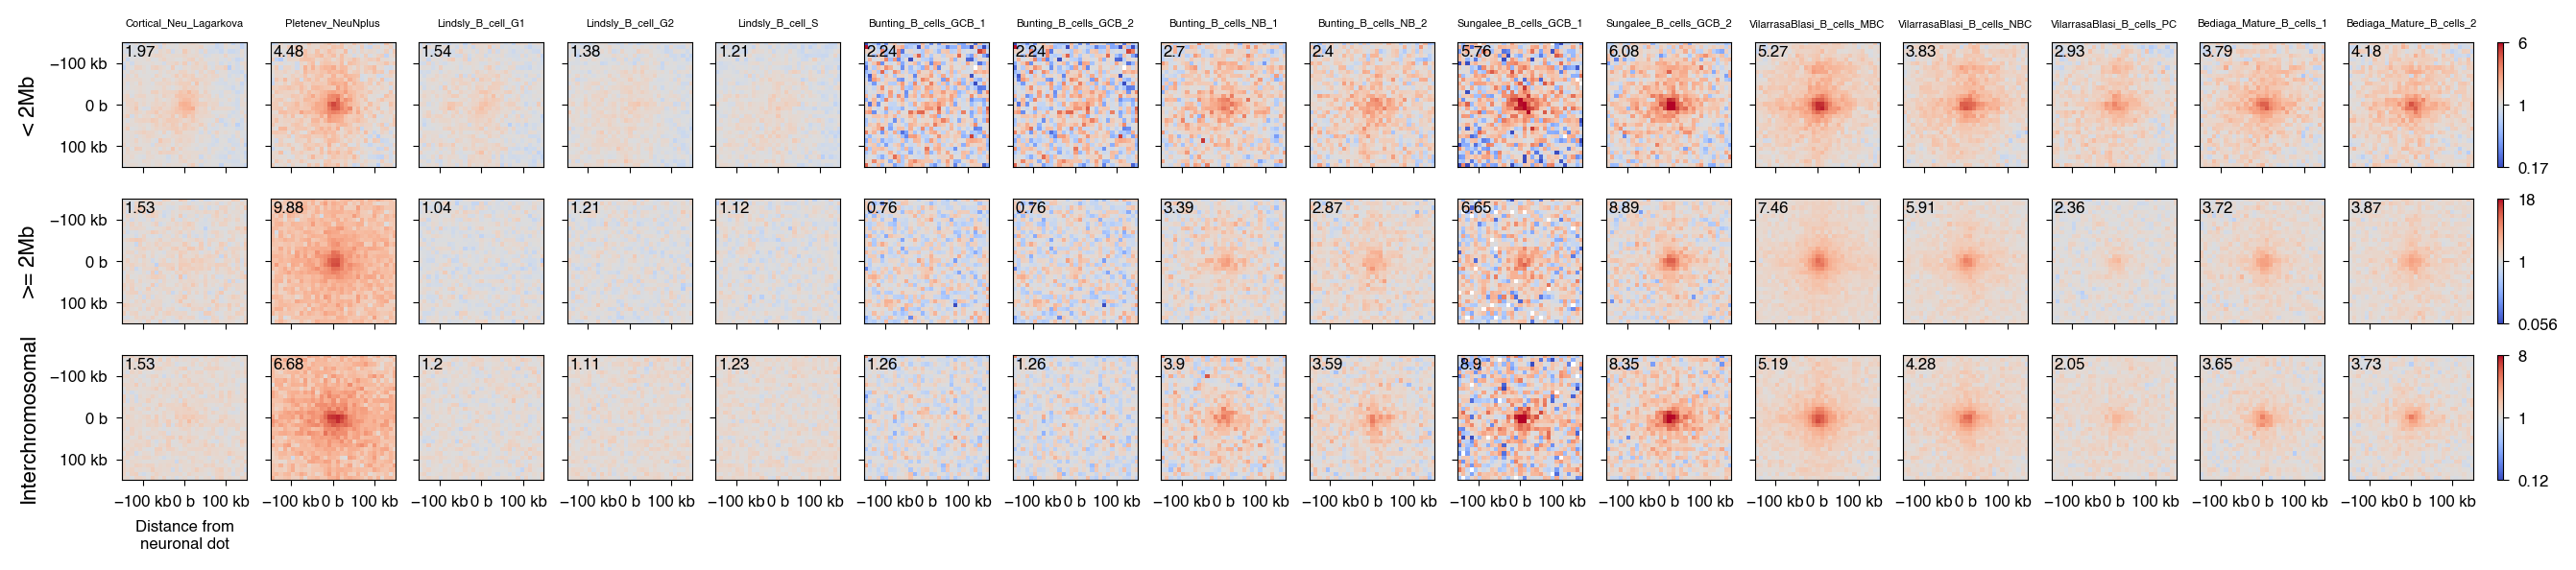

In [33]:
# Plot data for each ct separately
from matplotlib.colors import LogNorm
from coolpuppy.lib.numutils import get_enrichment
from matplotlib import ticker
from matplotlib.ticker import EngFormatter
bp_formatter = EngFormatter('b')

# Method 1: Modifying individual parameters

# plt.rcParams['axes.labelsize'] = 14      # Font size for x and y labels
# plt.rcParams['xtick.labelsize'] = 12    # Font size for x-axis tick labels
# plt.rcParams['ytick.labelsize'] = 12    # Font size for y-axis tick labels
# plt.rcParams['legend.fontsize'] = 10     # Font size for legend entries
# plt.rcParams['font.size'] = 12          # General font size for all text elements


def format_ticks(ax, x=True, y=True, rotate=True):
    if y:
        ax.yaxis.set_major_formatter(bp_formatter)
        ax.yaxis.set_major_locator(ticker.MultipleLocator(1e5))
    if x:
        ax.xaxis.set_major_formatter(bp_formatter)
        ax.xaxis.set_major_locator(ticker.MultipleLocator(1e5))
        ax.xaxis.tick_bottom()
        
        
nrows, ncols = 3, len(cts)
wr = [1]*ncols
wr.append(0.05)
fig, axs = plt.subplots(nrows, ncols+1, dpi=200, figsize=(ncols, nrows),
                        gridspec_kw={'width_ratios': wr})

vmax = {'short': 6, 'long': 18, 'trans': 8}
vmin = {k: 1/val for k, val in vmax.items()}
pup_grps = ['short', 'long', 'trans']

for i, pup in enumerate(pup_grps):
    for j, ct in enumerate(cts):
        arr = pup_hand[ct][pup]['data'][0]
        im = axs[i, j].imshow(
            arr, 
            cmap='coolwarm',
            norm=LogNorm(vmax=vmax[pup], vmin=vmin[pup]),
            extent=(-150000, 150000, 150000, -150000)
        )
        
        # Enrichment
        en = get_enrichment(arr, 0)
        axs[i, j].text(0.02, 0.98, round(en, 2), va='top', 
                       transform=axs[i, j].transAxes, fontsize=6)
        
        format_ticks(axs[i, j])
    
    # Colorbar
    plt.colorbar(im, cax=axs[i, ncols], ticks=[vmin[pup], 1, vmax[pup]], 
                 format=ticker.FuncFormatter(lambda x, pos: f"{x:.2g}"))
    axs[i, ncols].set_box_aspect(20)
    axs[i, ncols].minorticks_off()

# Ticks
for i in range(3):
    for j in range(1, ncols):
        axs[i, j].yaxis.set_ticklabels([])

# for i, j in [[0, 0], [0, 1], [1, 0], [1, 1]]:
#     axs[i, j].xaxis.set_ticklabels([])

for i in range(nrows-1):
    for j in range(ncols):
       axs[i, j].xaxis.set_ticklabels([]) 
    
# Labels
for i, ct in enumerate(cts):
    axs[0, i].set_title(ct, size=4)
# axs[0, 1].set_title(cts[1])
axs[0, 0].set_ylabel('< 2Mb', size=8)
axs[1, 0].set_ylabel('>= 2Mb', size=8)
axs[2, 0].set_ylabel('Interchromosomal', size=8)

axs[2, 0].set_xlabel('Distance from\nneuronal dot', size=6)
# axs[2, 1].set_xlabel('Distance from\nH3K27me3 peak')

# plt.tight_layout()

# plt.savefig('coolpup.hand.our_and_Hu2021_merged.pdf', bbox_inches='tight')
# plt.savefig('coolpup.hand.our.pdf', bbox_inches='tight')
# plt.savefig('coolpup.hand.Hu2021.pdf', bbox_inches='tight')
# plt.savefig('coolpup.hand.Tian2023.EN_IN.MTG.pdf', bbox_inches='tight')
# plt.savefig('coolpup.hand.iPSC_Lu_Choi_Rahman.pdf', bbox_inches='tight')

### Merged reps: Heart and B cells for presentation

In [14]:
clr_path = {
    "iPSC-derived_Neurons": '/tank/projects/mm_brain/2024_05_03/Ring1B_and_Lag_HiC/distiller_run_Neulag2/results/coolers_library/Neu_culture_Lag_mrg_all.hg38_drop_diag.1kb.mcool',
    "Postmortem_neurons": '/tank/projects/mm_brain/2024_05_03/Ring1B_and_Lag_HiC/distiller_run_pilot_Neulag/results/coolers_library/Pletenev2024_NeuNplus.sampled_mm.mcool',
    "Cardiomyocyte_heart": '/tank/projects/mm_polycomb_cells/datasets/GSE165303_heart_NF_merged.hg38.mapq_30.1000.mcool',
    "Cardiomyocyte_heart_DCM": '/tank/projects/mm_polycomb_cells/datasets/Feng_heart_DCM_merged.hg38.mapq_30.mcool', #dilated cardiomyopathy
    "Bunting_GCB_B_Cells": '/tank/projects/mm_polycomb_cells/datasets/Bunting_GCB_Bcells_merged.hg38.mapq_30.mcool',
    "Sungalee_GCB_B_cells": '/tank/projects/mm_polycomb_cells/datasets/Sungalee_B_cells_GCB_merged.hg38.mapq_30.mcool',
    "Mature_B_cells": '/tank/projects/mm_polycomb_cells/datasets/Bediaga_Mature_Bcells_merged.hg38.mapq_30.mcool'
    # "VilarrasaBlasi_B_cells_MBC": "/tank/projects/cell_hic_compare/mcool_merged/merged/MBC.hg38.mapq_30.1000.mcool",
    # "VilarrasaBlasi_B_cells_NBC": "/tank/projects/cell_hic_compare/mcool_merged/merged/NBC.hg38.mapq_30.1000.mcool",
    # "VilarrasaBlasi_B_cells_PC": "/tank/projects/cell_hic_compare/mcool_merged/merged/PC.hg38.mapq_30.1000.mcool",
}

cts = list(clr_path.keys()) # cell types

In [15]:
# Load hi-c matrices
# res = 10_000
res = 10_000

clrs = {ct: cooler.Cooler(clr_path[ct] + f'::resolutions/{res}') 
        for ct in cts}

In [16]:
# Set the resolution (in bp)
resolution = 1000
suffix = f"::resolutions/{resolution}"

# Loop through each file and count the number of contacts
for name, path in clr_path.items():
    try:
        clr = cooler.Cooler(path + suffix)
        num_contacts = clr.info['nnz']  # Number of non-zero contacts
        print(f"{name}: {num_contacts:,} contacts")
    except Exception as e:
        print(f"{name}: ERROR - {e}")

iPSC-derived_Neurons: 325,567,469 contacts
Postmortem_neurons: 97,607,431 contacts
Cardiomyocyte_heart: 636,007,153 contacts
Cardiomyocyte_heart_DCM: 647,356,849 contacts
Bunting_GCB_B_Cells: 62,844,618 contacts
Sungalee_GCB_B_cells: 58,311,539 contacts
Mature_B_cells: 335,162,389 contacts


In [24]:
# Load peaks and merge
hand_anch = pd.read_excel("/tank/projects/schizophrenia_2021/results/2024.01.10/Supp.Table_polycomb_dot_anchors.xlsx", na_values='-')

hand_anch.loc[:, 'mid_start'] = (hand_anch['start'] + hand_anch['end']) / 2 \
    - ((hand_anch['start'] + hand_anch['end']) / 2) % res
hand_anch.loc[:, 'mid_end'] = hand_anch['mid_start'] + res
hand_anch.loc[:, 'mid_start'] = hand_anch.loc[:, 'mid_start'].astype(int)
hand_anch.loc[:, 'mid_end'] = hand_anch.loc[:, 'mid_end'].astype(int)
    
hand_anch.head()

,chrom,start,end,genes,mid_start,mid_end
0,chr1,18630000,18640000,PAX7,18630000.0,18640000.0
1,chr1,24930000,24940000,RUNX3,24930000.0,24940000.0
2,chr1,44410000,44420000,RNF220,44410000.0,44420000.0
3,chr1,46480000,46490000,DMBX1,46480000.0,46490000.0
4,chr1,47230000,47240000,"TAL1,AL135960.1",47230000.0,47240000.0


In [25]:
# CIS obs/exp
cvd_10 = {}

for ct in cts:
    print(ct)
    cvd_10[ct] = expected_cis_cache(
        clrs[ct],
        smooth=False,
        nproc=10
    )

INFO:root:creating a Pool of 10 workers


iPSC-derived_Neurons
Pletenev_Postmortem_neurons
Cardiomyocyte_heart
Naive_B_Cells
Activated_B_cells


In [26]:
# TRANS obs/exp
trans_cvd_10 = {}

for ct in cts:
    print(ct)
    trans_cvd_10[ct] = expected_trans_cache(
        clrs[ct],
#         view_df=hg38_chromsizes_view,
        nproc=10
    )
    

INFO:root:creating a Pool of 10 workers


iPSC-derived_Neurons
Pletenev_Postmortem_neurons
Cardiomyocyte_heart
Naive_B_Cells
Activated_B_cells


In [27]:
# Split by distance
nproc=20
pup_hand = {ct: {} for ct in cts}
# pup_hand['NeuN+'] = {}
# pup_hand['NeuN-'] = {}

for ct in cts:
    print(ct)
    pup_hand[ct]['short'] = pileup_cache(
        clrs[ct], 
        hand_anch,
        expected_df=cvd_10[ct],
        flank=150000,
        mindist=3*res,
        maxdist=int(3e6),
        nproc=nproc
    );
    pup_hand[ct]['long'] = pileup_cache(
        clrs[ct], 
        hand_anch,
        expected_df=cvd_10[ct],
        flank=150000,
        mindist=int(3e6),
        nproc=nproc
    );
    pup_hand[ct]['trans'] = pileup_cache(
        clrs[ct], 
        hand_anch,
        expected_df=trans_cvd_10[ct],
        flank=150000,
        trans=True,
        nproc=nproc
    );

iPSC-derived_Neurons
Pletenev_Postmortem_neurons
Cardiomyocyte_heart


INFO:coolpuppy:('chr9', 'chr9'): 2
INFO:coolpuppy:('chr15', 'chr15'): 1
INFO:coolpuppy:('chr21', 'chr21'): 2
INFO:coolpuppy:('chr17', 'chr17'): 3
INFO:coolpuppy:('chr16', 'chr16'): 2
INFO:coolpuppy:('chr13', 'chr13'): 2
INFO:coolpuppy:('chr14', 'chr14'): 6
INFO:coolpuppy:('chr20', 'chr20'): 1
INFO:coolpuppy:('chr18', 'chr18'): 4
INFO:coolpuppy:('chr10', 'chr10'): 16
INFO:coolpuppy:('chr8', 'chr8'): 1
INFO:coolpuppy:('chr7', 'chr7'): 8
INFO:coolpuppy:('chr11', 'chr11'): 5
INFO:coolpuppy:('chr12', 'chr12'): 4
INFO:coolpuppy:('chr6', 'chr6'): 8
INFO:coolpuppy:('chr5', 'chr5'): 5
INFO:coolpuppy:('chr4', 'chr4'): 6
INFO:coolpuppy:('chr3', 'chr3'): 2
INFO:coolpuppy:('chr1', 'chr1'): 13
INFO:coolpuppy:('chr2', 'chr2'): 7
INFO:coolpuppy:('chrX', 'chrX'): 2
INFO:coolpuppy:Total number of piled up windows: 100
INFO:coolpuppy:('chr9', 'chr9'): 88
INFO:coolpuppy:('chr15', 'chr15'): 20
INFO:coolpuppy:('chr21', 'chr21'): 1
INFO:coolpuppy:('chr16', 'chr16'): 13
INFO:coolpuppy:('chr13', 'chr13'): 34
I

Naive_B_Cells


INFO:coolpuppy:('chr9', 'chr9'): 2
INFO:coolpuppy:('chr16', 'chr16'): 2
INFO:coolpuppy:('chr21', 'chr21'): 2
INFO:coolpuppy:('chr17', 'chr17'): 3
INFO:coolpuppy:('chr13', 'chr13'): 2
INFO:coolpuppy:('chr14', 'chr14'): 6
INFO:coolpuppy:('chr20', 'chr20'): 1
INFO:coolpuppy:('chr15', 'chr15'): 1
INFO:coolpuppy:('chr7', 'chr7'): 8
INFO:coolpuppy:('chr18', 'chr18'): 4
INFO:coolpuppy:('chr10', 'chr10'): 16
INFO:coolpuppy:('chr12', 'chr12'): 4
INFO:coolpuppy:('chr8', 'chr8'): 1
INFO:coolpuppy:('chr11', 'chr11'): 5
INFO:coolpuppy:('chr6', 'chr6'): 8
INFO:coolpuppy:('chr4', 'chr4'): 6
INFO:coolpuppy:('chr5', 'chr5'): 5
INFO:coolpuppy:('chr3', 'chr3'): 2
INFO:coolpuppy:('chr1', 'chr1'): 13
INFO:coolpuppy:('chrX', 'chrX'): 2
INFO:coolpuppy:('chr2', 'chr2'): 7
INFO:coolpuppy:Total number of piled up windows: 100
INFO:coolpuppy:('chr9', 'chr9'): 88
INFO:coolpuppy:('chr16', 'chr16'): 13
INFO:coolpuppy:('chr17', 'chr17'): 18
INFO:coolpuppy:('chr15', 'chr15'): 20
INFO:coolpuppy:('chr21', 'chr21'): 1
I

Activated_B_cells


INFO:coolpuppy:('chr1', 'chr1'): 13
INFO:coolpuppy:('chr2', 'chr2'): 7
INFO:coolpuppy:('chr3', 'chr3'): 2
INFO:coolpuppy:('chr4', 'chr4'): 6
INFO:coolpuppy:('chr6', 'chr6'): 8
INFO:coolpuppy:('chr5', 'chr5'): 5
INFO:coolpuppy:('chr7', 'chr7'): 8
INFO:coolpuppy:('chr9', 'chr9'): 2
INFO:coolpuppy:('chr8', 'chr8'): 1
INFO:coolpuppy:('chr10', 'chr10'): 16
INFO:coolpuppy:('chr11', 'chr11'): 5
INFO:coolpuppy:('chr13', 'chr13'): 2
INFO:coolpuppy:('chr14', 'chr14'): 6
INFO:coolpuppy:('chr16', 'chr16'): 2
INFO:coolpuppy:('chr12', 'chr12'): 4
INFO:coolpuppy:('chr15', 'chr15'): 1
INFO:coolpuppy:('chr20', 'chr20'): 1
INFO:coolpuppy:('chr17', 'chr17'): 3
INFO:coolpuppy:('chr21', 'chr21'): 2
INFO:coolpuppy:('chr18', 'chr18'): 4
INFO:coolpuppy:('chrX', 'chrX'): 2
INFO:coolpuppy:Total number of piled up windows: 100
INFO:coolpuppy:('chr3', 'chr3'): 43
INFO:coolpuppy:('chr1', 'chr1'): 218
INFO:coolpuppy:('chr2', 'chr2'): 203
INFO:coolpuppy:('chr4', 'chr4'): 85
INFO:coolpuppy:('chr8', 'chr8'): 27
INFO:c

Text(0.5, 0, 'Distance from\nneuronal dot')

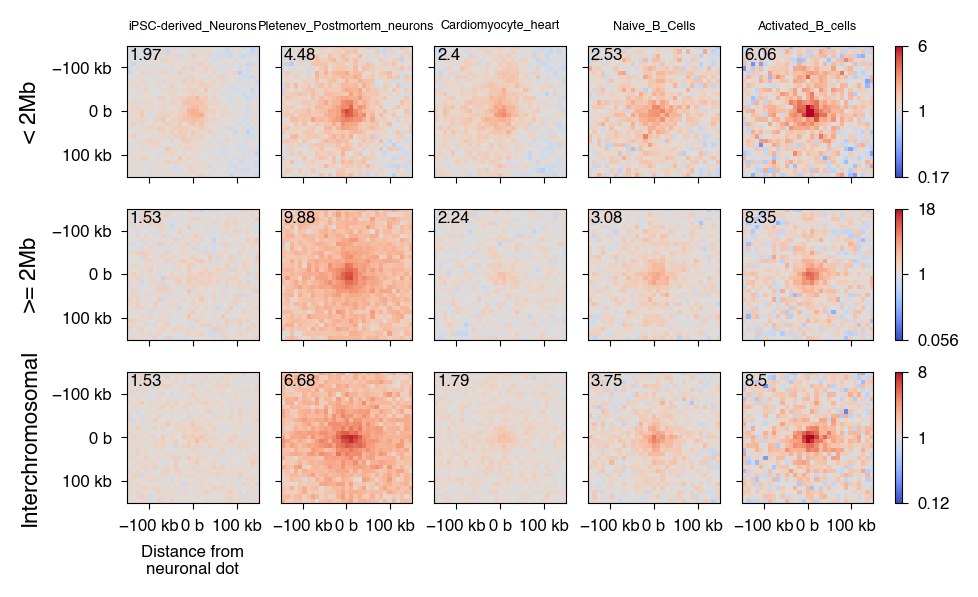

In [29]:
# Plot data for each ct separately
from matplotlib.colors import LogNorm
from coolpuppy.lib.numutils import get_enrichment
from matplotlib import ticker
from matplotlib.ticker import EngFormatter
bp_formatter = EngFormatter('b')

# Method 1: Modifying individual parameters

# plt.rcParams['axes.labelsize'] = 14      # Font size for x and y labels
# plt.rcParams['xtick.labelsize'] = 12    # Font size for x-axis tick labels
# plt.rcParams['ytick.labelsize'] = 12    # Font size for y-axis tick labels
# plt.rcParams['legend.fontsize'] = 10     # Font size for legend entries
# plt.rcParams['font.size'] = 12          # General font size for all text elements


def format_ticks(ax, x=True, y=True, rotate=True):
    if y:
        ax.yaxis.set_major_formatter(bp_formatter)
        ax.yaxis.set_major_locator(ticker.MultipleLocator(1e5))
    if x:
        ax.xaxis.set_major_formatter(bp_formatter)
        ax.xaxis.set_major_locator(ticker.MultipleLocator(1e5))
        ax.xaxis.tick_bottom()
        
        
nrows, ncols = 3, len(cts)
wr = [1]*ncols
wr.append(0.05)
fig, axs = plt.subplots(nrows, ncols+1, dpi=200, figsize=(ncols, nrows),
                        gridspec_kw={'width_ratios': wr})

vmax = {'short': 6, 'long': 18, 'trans': 8}
vmin = {k: 1/val for k, val in vmax.items()}
pup_grps = ['short', 'long', 'trans']

for i, pup in enumerate(pup_grps):
    for j, ct in enumerate(cts):
        arr = pup_hand[ct][pup]['data'][0]
        im = axs[i, j].imshow(
            arr, 
            cmap='coolwarm',
            norm=LogNorm(vmax=vmax[pup], vmin=vmin[pup]),
            extent=(-150000, 150000, 150000, -150000)
        )
        
        # Enrichment
        en = get_enrichment(arr, 0)
        axs[i, j].text(0.02, 0.98, round(en, 2), va='top', 
                       transform=axs[i, j].transAxes, fontsize=6)
        
        format_ticks(axs[i, j])
    
    # Colorbar
    plt.colorbar(im, cax=axs[i, ncols], ticks=[vmin[pup], 1, vmax[pup]], 
                 format=ticker.FuncFormatter(lambda x, pos: f"{x:.2g}"))
    axs[i, ncols].set_box_aspect(20)
    axs[i, ncols].minorticks_off()

# Ticks
for i in range(3):
    for j in range(1, ncols):
        axs[i, j].yaxis.set_ticklabels([])

# for i, j in [[0, 0], [0, 1], [1, 0], [1, 1]]:
#     axs[i, j].xaxis.set_ticklabels([])

for i in range(nrows-1):
    for j in range(ncols):
       axs[i, j].xaxis.set_ticklabels([]) 
    
# Labels
for i, ct in enumerate(cts):
    axs[0, i].set_title(ct, size=5)
# axs[0, 1].set_title(cts[1])
axs[0, 0].set_ylabel('< 2Mb', size=8)
axs[1, 0].set_ylabel('>= 2Mb', size=8)
axs[2, 0].set_ylabel('Interchromosomal', size=8)

axs[2, 0].set_xlabel('Distance from\nneuronal dot', size=6)
# axs[2, 1].set_xlabel('Distance from\nH3K27me3 peak')

# plt.tight_layout()

# plt.savefig('coolpup.hand.our_and_Hu2021_merged.pdf', bbox_inches='tight')
# plt.savefig('coolpup.hand.our.pdf', bbox_inches='tight')
# plt.savefig('coolpup.hand.Hu2021.pdf', bbox_inches='tight')
# plt.savefig('coolpup.hand.Tian2023.EN_IN.MTG.pdf', bbox_inches='tight')
# plt.savefig('coolpup.hand.iPSC_Lu_Choi_Rahman.pdf', bbox_inches='tight')

### Other: Heart, pancreatic, iPSC

In [8]:
clr_path = {
    "Cortical_Neu_Lagarkova": '/tank/projects/mm_brain/2024_05_03/Ring1B_and_Lag_HiC/distiller_run_Neulag2/results/coolers_library/Neu_culture_Lag_mrg_all.hg38_drop_diag.1kb.mcool',
    "Pletenev_NeuNplus": '/tank/projects/mm_brain/2024_05_03/Ring1B_and_Lag_HiC/distiller_run_pilot_Neulag/results/coolers_library/Pletenev2024_NeuNplus.sampled_mm.mcool',
    # "Feng_heart_DCM_1": '/tank/projects/kmorozov/open_source/hi-c/GSE165303_human_heart/GSE165303_heart_DCM_1.hg38.mapq_30.1000.mcool',
    # "Feng_heart_DCM_2": '/tank/projects/kmorozov/open_source/hi-c/GSE165303_human_heart/GSE165303_heart_DCM_2.hg38.mapq_30.1000.mcool',
    # "Feng_heart_NF_1": '/tank/projects/kmorozov/open_source/hi-c/GSE165303_human_heart/GSE165303_heart_NF_1.hg38.mapq_30.1000.mcool',
    # "Feng_heart_NF_2": '/tank/projects/kmorozov/open_source/hi-c/GSE165303_human_heart/GSE165303_heart_NF_2.hg38.mapq_30.1000.mcool',
    # CordazzoVargas_ dataset - GSE284598 human iPSC
    "CordazzoVargas_iPSC_1": '/tank/projects/kmorozov/open_source/hi-c/GSE284598_human_ipsc/GSE284598_iPSC_1.hg38.mapq_30.1000.mcool',
    "CordazzoVargas_iPSC_2": '/tank/projects/kmorozov/open_source/hi-c/GSE284598_human_ipsc/GSE284598_iPSC_2.hg38.mapq_30.1000.mcool',
    "CordazzoVargas_iPSC_3": '/tank/projects/kmorozov/open_source/hi-c/GSE284598_human_ipsc/GSE284598_iPSC_3.hg38.mapq_30.1000.mcool',
    # "Lindsly_B_cell_G1": '/tank/projects/kmorozov/open_source/hi-c/GSE159813_Bcell/GSE159813_B_cell_G1_phase.hg38.mapq_30.1000.mcool',
    # "Lindsly_B_cell_G2": '/tank/projects/kmorozov/open_source/hi-c/GSE159813_Bcell/GSE159813_B_cell_G2_phase.hg38.mapq_30.1000.mcool',
    # "Lindsly_B_cell_S": '/tank/projects/kmorozov/open_source/hi-c/GSE159813_Bcell/GSE159813_B_cell_S_phase.hg38.mapq_30.1000.mcool',
    # "Bunting_B_cells_GCB_1": '/tank/projects/kmorozov/open_source/hi-c/GSE84022_B_cell/GSE84022_B_cells_GCB_1.hg38.mapq_30.1000.mcool',
    # "Bunting_B_cells_GCB_2": '/tank/projects/kmorozov/open_source/hi-c/GSE84022_B_cell/GSE84022_B_cells_GCB_2.hg38.mapq_30.1000.mcool',
    # "Bunting_B_cells_NB_1": '/tank/projects/kmorozov/open_source/hi-c/GSE84022_B_cell/GSE84022_B_cells_NB_1.hg38.mapq_30.1000.mcool',
    # "Bunting_B_cells_NB_2": '/tank/projects/kmorozov/open_source/hi-c/GSE84022_B_cell/GSE84022_B_cells_NB_2.hg38.mapq_30.1000.mcool',
    # "Sungalee_B_cells_GCB_1": '/tank/projects/kmorozov/open_source/hi-c/GSE168470_B_cell/GSE168470_B_cells_GCB_1.hg38.mapq_30.1000.mcool',
    # "Sungalee_B_cells_GCB_2": '/tank/projects/kmorozov/open_source/hi-c/GSE168470_B_cell/GSE168470_B_cells_GCB_2.hg38.mapq_30.1000.mcool',
    "Anya_DS_pancr_cells_acinar": '/tank/projects/cell_hic_compare/mcool_merged/merged/HiC_acinar.hg38.mapq_30.1000.mcool',
    "Anya_DS_pancr_cells_alpha": "/tank/projects/cell_hic_compare/mcool_merged/merged/HiC_alpha.hg38.mapq_30.1000.mcool",
    "Anya_DS_pancr_cells_beta": "/tank/projects/cell_hic_compare/mcool_merged/merged/HiC_beta.hg38.mapq_30.1000.mcool",
    # "VilarrasaBlasi_B_cells_MBC": "/tank/projects/cell_hic_compare/mcool_merged/merged/MBC.hg38.mapq_30.1000.mcool",
    # "VilarrasaBlasi_B_cells_NBC": "/tank/projects/cell_hic_compare/mcool_merged/merged/NBC.hg38.mapq_30.1000.mcool",
    # "VilarrasaBlasi_B_cells_PC": "/tank/projects/cell_hic_compare/mcool_merged/merged/PC.hg38.mapq_30.1000.mcool",
    # # Bediaga_ dataset - B cells
    # "Bediaga_B_cells_1": '/tank/projects/kmorozov/open_source/hi-c/GSE126117_act_cd4_8/GSE126117_B_cells_1.hg38.mapq_30.1000.mcool',
    # "Bediaga_B_cells_2": '/tank/projects/kmorozov/open_source/hi-c/GSE126117_act_cd4_8/GSE126117_B_cells_2.hg38.mapq_30.1000.mcool',

    # # Yang_ dataset - GSE138767 CD4+ T cell activation time course
    # "Yang_CD4_T_cells_stim_1hr_1": '/tank/projects/kmorozov/open_source/hi-c/GSE138767_cd4_activation/GSE138767_primary_CD4_T_cells_stim_1hr_1.hg38.mapq_30.1000.mcool',
    # "Yang_CD4_T_cells_stim_1hr_2": '/tank/projects/kmorozov/open_source/hi-c/GSE138767_cd4_activation/GSE138767_primary_CD4_T_cells_stim_1hr_2.hg38.mapq_30.1000.mcool',
    # "Yang_CD4_T_cells_stim_4hr_1": '/tank/projects/kmorozov/open_source/hi-c/GSE138767_cd4_activation/GSE138767_primary_CD4_T_cells_stim_4hr_1.hg38.mapq_30.1000.mcool',
    # "Yang_CD4_T_cells_stim_4hr_2": '/tank/projects/kmorozov/open_source/hi-c/GSE138767_cd4_activation/GSE138767_primary_CD4_T_cells_stim_4hr_2.hg38.mapq_30.1000.mcool',
    # "Yang_CD4_T_cells_stim_20min_1": '/tank/projects/kmorozov/open_source/hi-c/GSE138767_cd4_activation/GSE138767_primary_CD4_T_cells_stim_20min_1.hg38.mapq_30.1000.mcool',
    # "Yang_CD4_T_cells_stim_20min_2": '/tank/projects/kmorozov/open_source/hi-c/GSE138767_cd4_activation/GSE138767_primary_CD4_T_cells_stim_20min_2.hg38.mapq_30.1000.mcool',
    # "Yang_CD4_T_cells_stim_24hr_1": '/tank/projects/kmorozov/open_source/hi-c/GSE138767_cd4_activation/GSE138767_primary_CD4_T_cells_stim_24hr_1.hg38.mapq_30.1000.mcool',
    # "Yang_CD4_T_cells_unstim_1": '/tank/projects/kmorozov/open_source/hi-c/GSE138767_cd4_activation/GSE138767_primary_CD4_T_cells_unstim_1.hg38.mapq_30.1000.mcool',
    # "Yang_CD4_T_cells_unstim_2": '/tank/projects/kmorozov/open_source/hi-c/GSE138767_cd4_activation/GSE138767_primary_CD4_T_cells_unstim_2.hg38.mapq_30.1000.mcool',
    
    # # Bediaga_ dataset - T cells
    # "Bediaga_activated_CD4_T_cells_1": '/tank/projects/kmorozov/open_source/hi-c/GSE126117_act_cd4_8/GSE126117_activated_CD4_T_cells_1.hg38.mapq_30.1000.mcool',
    # "Bediaga_activated_CD4_T_cells_2": '/tank/projects/kmorozov/open_source/hi-c/GSE126117_act_cd4_8/GSE126117_activated_CD4_T_cells_2.hg38.mapq_30.1000.mcool',
    # "Bediaga_activated_CD8_T_cells_1": '/tank/projects/kmorozov/open_source/hi-c/GSE126117_act_cd4_8/GSE126117_activated_CD8_T_cells_1.hg38.mapq_30.1000.mcool',
    # "Bediaga_activated_CD8_T_cells_2": '/tank/projects/kmorozov/open_source/hi-c/GSE126117_act_cd4_8/GSE126117_activated_CD8_T_cells_2.hg38.mapq_30.1000.mcool',
    # "Bediaga_naive_CD4_T_cells_1": '/tank/projects/kmorozov/open_source/hi-c/GSE126117_act_cd4_8/GSE126117_naive_CD4_T_cells_1.hg38.mapq_30.1000.mcool',
    # "Bediaga_naive_CD4_T_cells_2": '/tank/projects/kmorozov/open_source/hi-c/GSE126117_act_cd4_8/GSE126117_naive_CD4_T_cells_2.hg38.mapq_30.1000.mcool',
    # "Bediaga_naive_CD8_T_cells_1": '/tank/projects/kmorozov/open_source/hi-c/GSE126117_act_cd4_8/GSE126117_naive_CD8_T_cells_1.hg38.mapq_30.1000.mcool',
    # "Bediaga_naive_CD8_T_cells_2": '/tank/projects/kmorozov/open_source/hi-c/GSE126117_act_cd4_8/GSE126117_naive_CD8_T_cells_2.hg38.mapq_30.1000.mcool'

    # "PE_Neuron_rep2b": '/tank/projects/kmorozov/open_source/hi-c/iPSC_Hi-C/Neuron2b.hg38.mapq_30.1000.mcool',
    # "PE_NPC_rep1": '/tank/projects/kmorozov/open_source/hi-c/iPSC_Hi-C/NPC1.hg38.mapq_30.1000.mcool',
    # "PE_NPC_rep2a": '/tank/projects/kmorozov/open_source/hi-c/iPSC_Hi-C/NPC2a.hg38.mapq_30.1000.mcool',
    # "PE_NPC_rep2b": '/tank/projects/kmorozov/open_source/hi-c/iPSC_Hi-C/NPC2b.hg38.mapq_30.1000.mcool',
    # "PE_Glia_rep1": '/tank/projects/kmorozov/open_source/hi-c/iPSC_Hi-C/Glia1.hg38.mapq_30.1000.mcool',
    # "PE_Glia_rep2a": '/tank/projects/kmorozov/open_source/hi-c/iPSC_Hi-C/Glia2a.hg38.mapq_30.1000.mcool',
    # "PE_Glia_rep2b": '/tank/projects/kmorozov/open_source/hi-c/iPSC_Hi-C/Glia2b.hg38.mapq_30.1000.mcool',
    # "Lu2020_Neurons": "/tank/projects/schizophrenia_2021/hi-c/hNeurons_and_NPC/HiC_merged_hNeurons.hg38.mapq_30.1000.mcool",
    # # "Lu2020_NPC": "/tank/projects/schizophrenia_2021/hi-c/hNeurons_and_NPC/HiC_merged_NPC.hg38.mapq_30.1000.cool",
    # 'our_NeuN+': "NeuNplus.our.mcool",
    # 'our_NeuN-': "NeuNminus.our.mcool",
    # "Choi2020_iPSC_rep1": "/tank/projects/kmorozov/open_source/hi-c/GSE158382/SRR12694368.hg38.mapq_30.1000.mcool",
    # "Choi2020_iPSC_rep2": "/tank/projects/kmorozov/open_source/hi-c/GSE158382/SRR12694369.hg38.mapq_30.1000.mcool",
    # "Choi2020_NPC_rep1": "/tank/projects/kmorozov/open_source/hi-c/GSE158382/SRR12694370.hg38.mapq_30.1000.mcool",
    # "Choi2020_NPC_rep1": "/tank/projects/kmorozov/open_source/hi-c/GSE158382/SRR12694371.hg38.mapq_30.1000.mcool",   
    # "Rahman_iPSC_neurons": "/tank/projects/schizophrenia_2021/data/rahman2023/CRISPRi_Scrambled_A_DpnII-HinfI.mcool"
}

cts = list(clr_path.keys()) # cell types

In [9]:
# Load hi-c matrices
# res = 10_000
res = 10_000

clrs = {ct: cooler.Cooler(clr_path[ct] + f'::resolutions/{res}') 
        for ct in cts}

# Load peaks and merge
hand_anch = pd.read_excel("/tank/projects/schizophrenia_2021/results/2024.01.10/Supp.Table_polycomb_dot_anchors.xlsx", na_values='-')

hand_anch.loc[:, 'mid_start'] = (hand_anch['start'] + hand_anch['end']) / 2 \
    - ((hand_anch['start'] + hand_anch['end']) / 2) % res
hand_anch.loc[:, 'mid_end'] = hand_anch['mid_start'] + res
hand_anch.loc[:, 'mid_start'] = hand_anch.loc[:, 'mid_start'].astype(int)
hand_anch.loc[:, 'mid_end'] = hand_anch.loc[:, 'mid_end'].astype(int)
    
hand_anch.head()

# CIS obs/exp
cvd_10 = {}

for ct in cts:
    print(ct)
    cvd_10[ct] = expected_cis_cache(
        clrs[ct],
        smooth=False,
        nproc=10
    )
    
# TRANS obs/exp
trans_cvd_10 = {}

for ct in cts:
    print(ct)
    trans_cvd_10[ct] = expected_trans_cache(
        clrs[ct],
#         view_df=hg38_chromsizes_view,
        nproc=10
    )
    
# Set the resolution (in bp)
resolution = 1000
suffix = f"::resolutions/{resolution}"




Cortical_Neu_Lagarkova
Pletenev_NeuNplus
CordazzoVargas_iPSC_1
CordazzoVargas_iPSC_2
CordazzoVargas_iPSC_3
Anya_DS_pancr_cells_acinar
Anya_DS_pancr_cells_alpha
Anya_DS_pancr_cells_beta
Cortical_Neu_Lagarkova
Pletenev_NeuNplus
CordazzoVargas_iPSC_1
CordazzoVargas_iPSC_2
CordazzoVargas_iPSC_3
Anya_DS_pancr_cells_acinar
Anya_DS_pancr_cells_alpha
Anya_DS_pancr_cells_beta


In [10]:
# Loop through each file and count the number of contacts
for name, path in clr_path.items():
    try:
        clr = cooler.Cooler(path + suffix)
        num_contacts = clr.info['nnz']  # Number of non-zero contacts
        print(f"{name}: {num_contacts:,} contacts")
    except Exception as e:
        print(f"{name}: ERROR - {e}")
        

Cortical_Neu_Lagarkova: 325,567,469 contacts
Pletenev_NeuNplus: 97,607,431 contacts
CordazzoVargas_iPSC_1: 95,074,269 contacts
CordazzoVargas_iPSC_2: 139,734,408 contacts
CordazzoVargas_iPSC_3: 112,799,401 contacts
Anya_DS_pancr_cells_acinar: 2,975,638,133 contacts
Anya_DS_pancr_cells_alpha: 2,530,678,689 contacts
Anya_DS_pancr_cells_beta: 3,873,761,309 contacts


In [11]:
# Split by distance
nproc=20
pup_hand = {ct: {} for ct in cts}
# pup_hand['NeuN+'] = {}
# pup_hand['NeuN-'] = {}

for ct in cts:
    print(ct)
    pup_hand[ct]['short'] = pileup_cache(
        clrs[ct], 
        hand_anch,
        expected_df=cvd_10[ct],
        flank=150000,
        mindist=3*res,
        maxdist=int(3e6),
        nproc=nproc
    );
    pup_hand[ct]['long'] = pileup_cache(
        clrs[ct], 
        hand_anch,
        expected_df=cvd_10[ct],
        flank=150000,
        mindist=int(3e6),
        nproc=nproc
    );
    pup_hand[ct]['trans'] = pileup_cache(
        clrs[ct], 
        hand_anch,
        expected_df=trans_cvd_10[ct],
        flank=150000,
        trans=True,
        nproc=nproc
    );

Cortical_Neu_Lagarkova
Pletenev_NeuNplus
CordazzoVargas_iPSC_1
CordazzoVargas_iPSC_2
CordazzoVargas_iPSC_3
Anya_DS_pancr_cells_acinar
Anya_DS_pancr_cells_alpha
Anya_DS_pancr_cells_beta


Text(0.5, 0, 'Distance from\nneuronal dot')

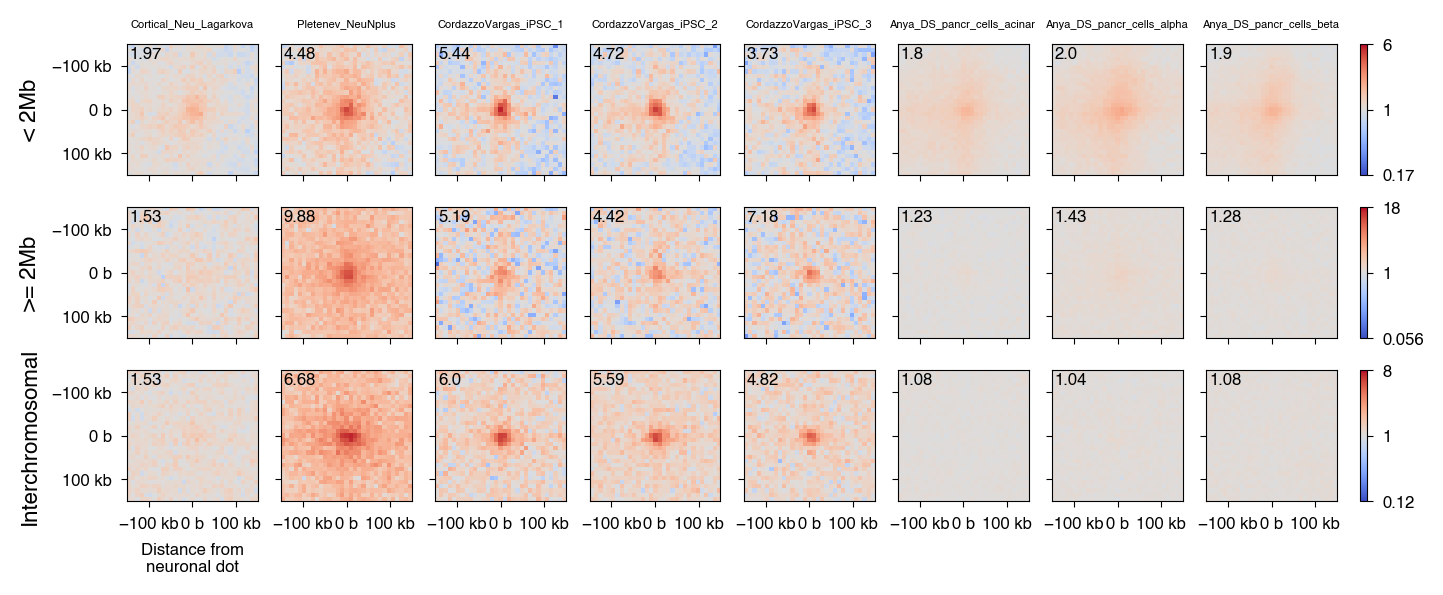

In [12]:
# Plot data for each ct separately
from matplotlib.colors import LogNorm
from coolpuppy.lib.numutils import get_enrichment
from matplotlib import ticker
from matplotlib.ticker import EngFormatter
bp_formatter = EngFormatter('b')

# Method 1: Modifying individual parameters

# plt.rcParams['axes.labelsize'] = 14      # Font size for x and y labels
# plt.rcParams['xtick.labelsize'] = 12    # Font size for x-axis tick labels
# plt.rcParams['ytick.labelsize'] = 12    # Font size for y-axis tick labels
# plt.rcParams['legend.fontsize'] = 10     # Font size for legend entries
# plt.rcParams['font.size'] = 12          # General font size for all text elements


def format_ticks(ax, x=True, y=True, rotate=True):
    if y:
        ax.yaxis.set_major_formatter(bp_formatter)
        ax.yaxis.set_major_locator(ticker.MultipleLocator(1e5))
    if x:
        ax.xaxis.set_major_formatter(bp_formatter)
        ax.xaxis.set_major_locator(ticker.MultipleLocator(1e5))
        ax.xaxis.tick_bottom()
        
        
nrows, ncols = 3, len(cts)
wr = [1]*ncols
wr.append(0.05)
fig, axs = plt.subplots(nrows, ncols+1, dpi=200, figsize=(ncols, nrows),
                        gridspec_kw={'width_ratios': wr})

vmax = {'short': 6, 'long': 18, 'trans': 8}
vmin = {k: 1/val for k, val in vmax.items()}
pup_grps = ['short', 'long', 'trans']

for i, pup in enumerate(pup_grps):
    for j, ct in enumerate(cts):
        arr = pup_hand[ct][pup]['data'][0]
        im = axs[i, j].imshow(
            arr, 
            cmap='coolwarm',
            norm=LogNorm(vmax=vmax[pup], vmin=vmin[pup]),
            extent=(-150000, 150000, 150000, -150000)
        )
        
        # Enrichment
        en = get_enrichment(arr, 0)
        axs[i, j].text(0.02, 0.98, round(en, 2), va='top', 
                       transform=axs[i, j].transAxes, fontsize=6)
        
        format_ticks(axs[i, j])
    
    # Colorbar
    plt.colorbar(im, cax=axs[i, ncols], ticks=[vmin[pup], 1, vmax[pup]], 
                 format=ticker.FuncFormatter(lambda x, pos: f"{x:.2g}"))
    axs[i, ncols].set_box_aspect(20)
    axs[i, ncols].minorticks_off()

# Ticks
for i in range(3):
    for j in range(1, ncols):
        axs[i, j].yaxis.set_ticklabels([])

# for i, j in [[0, 0], [0, 1], [1, 0], [1, 1]]:
#     axs[i, j].xaxis.set_ticklabels([])

for i in range(nrows-1):
    for j in range(ncols):
       axs[i, j].xaxis.set_ticklabels([]) 
    
# Labels
for i, ct in enumerate(cts):
    axs[0, i].set_title(ct, size=4)
# axs[0, 1].set_title(cts[1])
axs[0, 0].set_ylabel('< 2Mb', size=8)
axs[1, 0].set_ylabel('>= 2Mb', size=8)
axs[2, 0].set_ylabel('Interchromosomal', size=8)

axs[2, 0].set_xlabel('Distance from\nneuronal dot', size=6)
# axs[2, 1].set_xlabel('Distance from\nH3K27me3 peak')

# plt.tight_layout()

# plt.savefig('coolpup.hand.our_and_Hu2021_merged.pdf', bbox_inches='tight')
# plt.savefig('coolpup.hand.our.pdf', bbox_inches='tight')
# plt.savefig('coolpup.hand.Hu2021.pdf', bbox_inches='tight')
# plt.savefig('coolpup.hand.Tian2023.EN_IN.MTG.pdf', bbox_inches='tight')
# plt.savefig('coolpup.hand.iPSC_Lu_Choi_Rahman.pdf', bbox_inches='tight')

### T_Cells

In [13]:
clr_path = {
    "Cortical_Neu_Lagarkova": '/tank/projects/mm_brain/2024_05_03/Ring1B_and_Lag_HiC/distiller_run_Neulag2/results/coolers_library/Neu_culture_Lag_mrg_all.hg38_drop_diag.1kb.mcool',
    "Pletenev_NeuNplus": '/tank/projects/mm_brain/2024_05_03/Ring1B_and_Lag_HiC/distiller_run_pilot_Neulag/results/coolers_library/Pletenev2024_NeuNplus.sampled_mm.mcool',
    # "Lindsly_B_cell_G1": '/tank/projects/kmorozov/open_source/hi-c/GSE159813_Bcell/GSE159813_B_cell_G1_phase.hg38.mapq_30.1000.mcool',
    # "Lindsly_B_cell_G2": '/tank/projects/kmorozov/open_source/hi-c/GSE159813_Bcell/GSE159813_B_cell_G2_phase.hg38.mapq_30.1000.mcool',
    # "Lindsly_B_cell_S": '/tank/projects/kmorozov/open_source/hi-c/GSE159813_Bcell/GSE159813_B_cell_S_phase.hg38.mapq_30.1000.mcool',
    # # "Feng_heart_DCM_1": '/tank/projects/kmorozov/open_source/hi-c/GSE165303_human_heart/GSE165303_heart_DCM_1.hg38.mapq_30.1000.mcool',
    # # "Feng_heart_DCM_2": '/tank/projects/kmorozov/open_source/hi-c/GSE165303_human_heart/GSE165303_heart_DCM_2.hg38.mapq_30.1000.mcool',
    # # "Feng_heart_NF_1": '/tank/projects/kmorozov/open_source/hi-c/GSE165303_human_heart/GSE165303_heart_NF_1.hg38.mapq_30.1000.mcool',
    # # "Feng_heart_NF_2": '/tank/projects/kmorozov/open_source/hi-c/GSE165303_human_heart/GSE165303_heart_NF_2.hg38.mapq_30.1000.mcool',
    # "Bunting_B_cells_GCB_1": '/tank/projects/kmorozov/open_source/hi-c/GSE84022_B_cell/GSE84022_B_cells_GCB_1.hg38.mapq_30.1000.mcool',
    # "Bunting_B_cells_GCB_2": '/tank/projects/kmorozov/open_source/hi-c/GSE84022_B_cell/GSE84022_B_cells_GCB_2.hg38.mapq_30.1000.mcool',
    # "Bunting_B_cells_NB_1": '/tank/projects/kmorozov/open_source/hi-c/GSE84022_B_cell/GSE84022_B_cells_NB_1.hg38.mapq_30.1000.mcool',
    # "Bunting_B_cells_NB_2": '/tank/projects/kmorozov/open_source/hi-c/GSE84022_B_cell/GSE84022_B_cells_NB_2.hg38.mapq_30.1000.mcool',
    # "Sungalee_B_cells_GCB_1": '/tank/projects/kmorozov/open_source/hi-c/GSE168470_B_cell/GSE168470_B_cells_GCB_1.hg38.mapq_30.1000.mcool',
    # "Sungalee_B_cells_GCB_2": '/tank/projects/kmorozov/open_source/hi-c/GSE168470_B_cell/GSE168470_B_cells_GCB_2.hg38.mapq_30.1000.mcool',
    # # "Anya_DS_pancr_cells_acinar": '/tank/projects/cell_hic_compare/mcool_merged/merged/HiC_acinar.hg38.mapq_30.1000.mcool',
    # # "Anya_DS_pancr_cells_alpha": "/tank/projects/cell_hic_compare/mcool_merged/merged/HiC_alpha.hg38.mapq_30.1000.mcool",
    # # "Anya_DS_pancr_cells_beta": "/tank/projects/cell_hic_compare/mcool_merged/merged/HiC_beta.hg38.mapq_30.1000.mcool",
    # "VilarrasaBlasi_B_cells_MBC": "/tank/projects/cell_hic_compare/mcool_merged/merged/MBC.hg38.mapq_30.1000.mcool",
    # "VilarrasaBlasi_B_cells_NBC": "/tank/projects/cell_hic_compare/mcool_merged/merged/NBC.hg38.mapq_30.1000.mcool",
    # "VilarrasaBlasi_B_cells_PC": "/tank/projects/cell_hic_compare/mcool_merged/merged/PC.hg38.mapq_30.1000.mcool",
    # # Bediaga_ dataset - B cells
    # "Bediaga_B_cells_1": '/tank/projects/kmorozov/open_source/hi-c/GSE126117_act_cd4_8/GSE126117_B_cells_1.hg38.mapq_30.1000.mcool',
    # "Bediaga_B_cells_2": '/tank/projects/kmorozov/open_source/hi-c/GSE126117_act_cd4_8/GSE126117_B_cells_2.hg38.mapq_30.1000.mcool',

    # Yang_ dataset - GSE138767 CD4+ T cell activation time course
    "Yang_CD4_T_cells_stim_1hr_1": '/tank/projects/kmorozov/open_source/hi-c/GSE138767_cd4_activation/GSE138767_primary_CD4_T_cells_stim_1hr_1.hg38.mapq_30.1000.mcool',
    "Yang_CD4_T_cells_stim_1hr_2": '/tank/projects/kmorozov/open_source/hi-c/GSE138767_cd4_activation/GSE138767_primary_CD4_T_cells_stim_1hr_2.hg38.mapq_30.1000.mcool',
    "Yang_CD4_T_cells_stim_4hr_1": '/tank/projects/kmorozov/open_source/hi-c/GSE138767_cd4_activation/GSE138767_primary_CD4_T_cells_stim_4hr_1.hg38.mapq_30.1000.mcool',
    "Yang_CD4_T_cells_stim_4hr_2": '/tank/projects/kmorozov/open_source/hi-c/GSE138767_cd4_activation/GSE138767_primary_CD4_T_cells_stim_4hr_2.hg38.mapq_30.1000.mcool',
    "Yang_CD4_T_cells_stim_20min_1": '/tank/projects/kmorozov/open_source/hi-c/GSE138767_cd4_activation/GSE138767_primary_CD4_T_cells_stim_20min_1.hg38.mapq_30.1000.mcool',
    "Yang_CD4_T_cells_stim_20min_2": '/tank/projects/kmorozov/open_source/hi-c/GSE138767_cd4_activation/GSE138767_primary_CD4_T_cells_stim_20min_2.hg38.mapq_30.1000.mcool',
    "Yang_CD4_T_cells_stim_24hr_1": '/tank/projects/kmorozov/open_source/hi-c/GSE138767_cd4_activation/GSE138767_primary_CD4_T_cells_stim_24hr_1.hg38.mapq_30.1000.mcool',
    "Yang_CD4_T_cells_unstim_1": '/tank/projects/kmorozov/open_source/hi-c/GSE138767_cd4_activation/GSE138767_primary_CD4_T_cells_unstim_1.hg38.mapq_30.1000.mcool',
    "Yang_CD4_T_cells_unstim_2": '/tank/projects/kmorozov/open_source/hi-c/GSE138767_cd4_activation/GSE138767_primary_CD4_T_cells_unstim_2.hg38.mapq_30.1000.mcool',
    
    # Bediaga_ dataset - T cells
    "Bediaga_activated_CD4_T_cells_1": '/tank/projects/kmorozov/open_source/hi-c/GSE126117_act_cd4_8/GSE126117_activated_CD4_T_cells_1.hg38.mapq_30.1000.mcool',
    "Bediaga_activated_CD4_T_cells_2": '/tank/projects/kmorozov/open_source/hi-c/GSE126117_act_cd4_8/GSE126117_activated_CD4_T_cells_2.hg38.mapq_30.1000.mcool',
    "Bediaga_activated_CD8_T_cells_1": '/tank/projects/kmorozov/open_source/hi-c/GSE126117_act_cd4_8/GSE126117_activated_CD8_T_cells_1.hg38.mapq_30.1000.mcool',
    "Bediaga_activated_CD8_T_cells_2": '/tank/projects/kmorozov/open_source/hi-c/GSE126117_act_cd4_8/GSE126117_activated_CD8_T_cells_2.hg38.mapq_30.1000.mcool',
    "Bediaga_naive_CD4_T_cells_1": '/tank/projects/kmorozov/open_source/hi-c/GSE126117_act_cd4_8/GSE126117_naive_CD4_T_cells_1.hg38.mapq_30.1000.mcool',
    "Bediaga_naive_CD4_T_cells_2": '/tank/projects/kmorozov/open_source/hi-c/GSE126117_act_cd4_8/GSE126117_naive_CD4_T_cells_2.hg38.mapq_30.1000.mcool',
    "Bediaga_naive_CD8_T_cells_1": '/tank/projects/kmorozov/open_source/hi-c/GSE126117_act_cd4_8/GSE126117_naive_CD8_T_cells_1.hg38.mapq_30.1000.mcool',
    "Bediaga_naive_CD8_T_cells_2": '/tank/projects/kmorozov/open_source/hi-c/GSE126117_act_cd4_8/GSE126117_naive_CD8_T_cells_2.hg38.mapq_30.1000.mcool'

    # "PE_Neuron_rep2b": '/tank/projects/kmorozov/open_source/hi-c/iPSC_Hi-C/Neuron2b.hg38.mapq_30.1000.mcool',
    # "PE_NPC_rep1": '/tank/projects/kmorozov/open_source/hi-c/iPSC_Hi-C/NPC1.hg38.mapq_30.1000.mcool',
    # "PE_NPC_rep2a": '/tank/projects/kmorozov/open_source/hi-c/iPSC_Hi-C/NPC2a.hg38.mapq_30.1000.mcool',
    # "PE_NPC_rep2b": '/tank/projects/kmorozov/open_source/hi-c/iPSC_Hi-C/NPC2b.hg38.mapq_30.1000.mcool',
    # "PE_Glia_rep1": '/tank/projects/kmorozov/open_source/hi-c/iPSC_Hi-C/Glia1.hg38.mapq_30.1000.mcool',
    # "PE_Glia_rep2a": '/tank/projects/kmorozov/open_source/hi-c/iPSC_Hi-C/Glia2a.hg38.mapq_30.1000.mcool',
    # "PE_Glia_rep2b": '/tank/projects/kmorozov/open_source/hi-c/iPSC_Hi-C/Glia2b.hg38.mapq_30.1000.mcool',
    # "Lu2020_Neurons": "/tank/projects/schizophrenia_2021/hi-c/hNeurons_and_NPC/HiC_merged_hNeurons.hg38.mapq_30.1000.mcool",
    # # "Lu2020_NPC": "/tank/projects/schizophrenia_2021/hi-c/hNeurons_and_NPC/HiC_merged_NPC.hg38.mapq_30.1000.cool",
    # 'our_NeuN+': "NeuNplus.our.mcool",
    # 'our_NeuN-': "NeuNminus.our.mcool",
    # "Choi2020_iPSC_rep1": "/tank/projects/kmorozov/open_source/hi-c/GSE158382/SRR12694368.hg38.mapq_30.1000.mcool",
    # "Choi2020_iPSC_rep2": "/tank/projects/kmorozov/open_source/hi-c/GSE158382/SRR12694369.hg38.mapq_30.1000.mcool",
    # "Choi2020_NPC_rep1": "/tank/projects/kmorozov/open_source/hi-c/GSE158382/SRR12694370.hg38.mapq_30.1000.mcool",
    # "Choi2020_NPC_rep1": "/tank/projects/kmorozov/open_source/hi-c/GSE158382/SRR12694371.hg38.mapq_30.1000.mcool",   
    # "Rahman_iPSC_neurons": "/tank/projects/schizophrenia_2021/data/rahman2023/CRISPRi_Scrambled_A_DpnII-HinfI.mcool"
}

cts = list(clr_path.keys()) # cell types

In [14]:
# Load hi-c matrices
# res = 10_000
res = 10_000

clrs = {ct: cooler.Cooler(clr_path[ct] + f'::resolutions/{res}') 
        for ct in cts}

# Load peaks and merge
hand_anch = pd.read_excel("/tank/projects/schizophrenia_2021/results/2024.01.10/Supp.Table_polycomb_dot_anchors.xlsx", na_values='-')

hand_anch.loc[:, 'mid_start'] = (hand_anch['start'] + hand_anch['end']) / 2 \
    - ((hand_anch['start'] + hand_anch['end']) / 2) % res
hand_anch.loc[:, 'mid_end'] = hand_anch['mid_start'] + res
hand_anch.loc[:, 'mid_start'] = hand_anch.loc[:, 'mid_start'].astype(int)
hand_anch.loc[:, 'mid_end'] = hand_anch.loc[:, 'mid_end'].astype(int)
    
hand_anch.head()

# CIS obs/exp
cvd_10 = {}

for ct in cts:
    print(ct)
    cvd_10[ct] = expected_cis_cache(
        clrs[ct],
        smooth=False,
        nproc=10
    )
    
# TRANS obs/exp
trans_cvd_10 = {}

for ct in cts:
    print(ct)
    trans_cvd_10[ct] = expected_trans_cache(
        clrs[ct],
#         view_df=hg38_chromsizes_view,
        nproc=10
    )
    
# Set the resolution (in bp)
resolution = 1000
suffix = f"::resolutions/{resolution}"

INFO:root:creating a Pool of 10 workers


Cortical_Neu_Lagarkova
Pletenev_NeuNplus
Yang_CD4_T_cells_stim_1hr_1


INFO:root:creating a Pool of 10 workers


Yang_CD4_T_cells_stim_1hr_2


INFO:root:creating a Pool of 10 workers


Yang_CD4_T_cells_stim_4hr_1


... (58 outputs left out)

INFO:root:creating a Pool of 10 workers


Bediaga_naive_CD8_T_cells_1


INFO:root:creating a Pool of 10 workers


Bediaga_naive_CD8_T_cells_2


In [15]:
# Loop through each file and count the number of contacts
for name, path in clr_path.items():
    try:
        clr = cooler.Cooler(path + suffix)
        num_contacts = clr.info['nnz']  # Number of non-zero contacts
        print(f"{name}: {num_contacts:,} contacts")
    except Exception as e:
        print(f"{name}: ERROR - {e}")

Cortical_Neu_Lagarkova: 325,567,469 contacts
Pletenev_NeuNplus: 97,607,431 contacts
Yang_CD4_T_cells_stim_1hr_1: 123,859,115 contacts
Yang_CD4_T_cells_stim_1hr_2: 103,220,190 contacts
Yang_CD4_T_cells_stim_4hr_1: 121,426,079 contacts
Yang_CD4_T_cells_stim_4hr_2: 78,430,606 contacts
Yang_CD4_T_cells_stim_20min_1: 135,381,828 contacts
Yang_CD4_T_cells_stim_20min_2: 88,203,509 contacts
Yang_CD4_T_cells_stim_24hr_1: 113,367,455 contacts
Yang_CD4_T_cells_unstim_1: 115,790,749 contacts
Yang_CD4_T_cells_unstim_2: 90,882,203 contacts
Bediaga_activated_CD4_T_cells_1: 77,040,032 contacts
Bediaga_activated_CD4_T_cells_2: 55,074,894 contacts
Bediaga_activated_CD8_T_cells_1: 130,615,580 contacts
Bediaga_activated_CD8_T_cells_2: 69,473,921 contacts
Bediaga_naive_CD4_T_cells_1: 136,229,964 contacts
Bediaga_naive_CD4_T_cells_2: 156,119,459 contacts
Bediaga_naive_CD8_T_cells_1: 146,984,145 contacts
Bediaga_naive_CD8_T_cells_2: 136,735,306 contacts


In [16]:
# Split by distance
nproc=20
pup_hand = {ct: {} for ct in cts}
# pup_hand['NeuN+'] = {}
# pup_hand['NeuN-'] = {}

for ct in cts:
    print(ct)
    pup_hand[ct]['short'] = pileup_cache(
        clrs[ct], 
        hand_anch,
        expected_df=cvd_10[ct],
        flank=150000,
        mindist=3*res,
        maxdist=int(3e6),
        nproc=nproc
    );
    pup_hand[ct]['long'] = pileup_cache(
        clrs[ct], 
        hand_anch,
        expected_df=cvd_10[ct],
        flank=150000,
        mindist=int(3e6),
        nproc=nproc
    );
    pup_hand[ct]['trans'] = pileup_cache(
        clrs[ct], 
        hand_anch,
        expected_df=trans_cvd_10[ct],
        flank=150000,
        trans=True,
        nproc=nproc
    );

Cortical_Neu_Lagarkova
Pletenev_NeuNplus
Yang_CD4_T_cells_stim_1hr_1


INFO:coolpuppy:('chr9', 'chr9'): 2
INFO:coolpuppy:('chr15', 'chr15'): 1
INFO:coolpuppy:('chr8', 'chr8'): 1
INFO:coolpuppy:('chr1', 'chr1'): 13
INFO:coolpuppy:('chr10', 'chr10'): 16
INFO:coolpuppy:('chr21', 'chr21'): 2
INFO:coolpuppy:('chr7', 'chr7'): 8
INFO:coolpuppy:('chr11', 'chr11'): 5
INFO:coolpuppy:('chr20', 'chr20'): 1
INFO:coolpuppy:('chr5', 'chr5'): 5
INFO:coolpuppy:('chr4', 'chr4'): 6
INFO:coolpuppy:('chr17', 'chr17'): 3
INFO:coolpuppy:('chr14', 'chr14'): 6
INFO:coolpuppy:('chr16', 'chr16'): 2
INFO:coolpuppy:('chr3', 'chr3'): 2
INFO:coolpuppy:('chr13', 'chr13'): 2
INFO:coolpuppy:('chr2', 'chr2'): 7
INFO:coolpuppy:('chr6', 'chr6'): 8
INFO:coolpuppy:('chr12', 'chr12'): 4
INFO:coolpuppy:('chr18', 'chr18'): 4
INFO:coolpuppy:('chrX', 'chrX'): 2
INFO:coolpuppy:Total number of piled up windows: 100
INFO:coolpuppy:('chr9', 'chr9'): 88
INFO:coolpuppy:('chr14', 'chr14'): 30
INFO:coolpuppy:('chr11', 'chr11'): 31
INFO:coolpuppy:('chr6', 'chr6'): 128
INFO:coolpuppy:('chr15', 'chr15'): 20
I

Yang_CD4_T_cells_stim_1hr_2


INFO:coolpuppy:('chr4', 'chr4'): 6
INFO:coolpuppy:('chr10', 'chr10'): 16
INFO:coolpuppy:('chr5', 'chr5'): 5
INFO:coolpuppy:('chr9', 'chr9'): 2
INFO:coolpuppy:('chr15', 'chr15'): 1
INFO:coolpuppy:('chr6', 'chr6'): 8
INFO:coolpuppy:('chr3', 'chr3'): 2
INFO:coolpuppy:('chr8', 'chr8'): 1
INFO:coolpuppy:('chr12', 'chr12'): 4
INFO:coolpuppy:('chr7', 'chr7'): 8
INFO:coolpuppy:('chr17', 'chr17'): 3
INFO:coolpuppy:('chr1', 'chr1'): 13
INFO:coolpuppy:('chr16', 'chr16'): 2
INFO:coolpuppy:('chr11', 'chr11'): 5
INFO:coolpuppy:('chr14', 'chr14'): 6
INFO:coolpuppy:('chr2', 'chr2'): 7
INFO:coolpuppy:('chr20', 'chr20'): 1
INFO:coolpuppy:('chr13', 'chr13'): 2
INFO:coolpuppy:('chr18', 'chr18'): 4
INFO:coolpuppy:('chr21', 'chr21'): 2
INFO:coolpuppy:('chrX', 'chrX'): 2
INFO:coolpuppy:Total number of piled up windows: 100
INFO:coolpuppy:('chr14', 'chr14'): 30
INFO:coolpuppy:('chr9', 'chr9'): 88
INFO:coolpuppy:('chr5', 'chr5'): 131
INFO:coolpuppy:('chr10', 'chr10'): 120
INFO:coolpuppy:('chr6', 'chr6'): 128
I

Yang_CD4_T_cells_stim_4hr_1


INFO:coolpuppy:('chr9', 'chr9'): 2
INFO:coolpuppy:('chr6', 'chr6'): 8
INFO:coolpuppy:('chr7', 'chr7'): 8
INFO:coolpuppy:('chr15', 'chr15'): 1
INFO:coolpuppy:('chr21', 'chr21'): 2
INFO:coolpuppy:('chr1', 'chr1'): 13
INFO:coolpuppy:('chr11', 'chr11'): 5
INFO:coolpuppy:('chr18', 'chr18'): 4
INFO:coolpuppy:('chr5', 'chr5'): 5
INFO:coolpuppy:('chr10', 'chr10'): 16
INFO:coolpuppy:('chr16', 'chr16'): 2
INFO:coolpuppy:('chr14', 'chr14'): 6
INFO:coolpuppy:('chr17', 'chr17'): 3
INFO:coolpuppy:('chr20', 'chr20'): 1
INFO:coolpuppy:('chr8', 'chr8'): 1
INFO:coolpuppy:('chr13', 'chr13'): 2
INFO:coolpuppy:('chr2', 'chr2'): 7
INFO:coolpuppy:('chr4', 'chr4'): 6
INFO:coolpuppy:('chr12', 'chr12'): 4
INFO:coolpuppy:('chr3', 'chr3'): 2
INFO:coolpuppy:('chrX', 'chrX'): 2
INFO:coolpuppy:Total number of piled up windows: 100
INFO:coolpuppy:('chr9', 'chr9'): 88
INFO:coolpuppy:('chr8', 'chr8'): 27
INFO:coolpuppy:('chr5', 'chr5'): 131
INFO:coolpuppy:('chr7', 'chr7'): 70
INFO:coolpuppy:('chr11', 'chr11'): 31
INFO:

... (24 outputs left out)

Bediaga_naive_CD8_T_cells_1


INFO:coolpuppy:('chr7', 'chr7'): 8
INFO:coolpuppy:('chr8', 'chr8'): 1
INFO:coolpuppy:('chr11', 'chr11'): 5
INFO:coolpuppy:('chr3', 'chr3'): 2
INFO:coolpuppy:('chr17', 'chr17'): 3
INFO:coolpuppy:('chr9', 'chr9'): 2
INFO:coolpuppy:('chr13', 'chr13'): 2
INFO:coolpuppy:('chr4', 'chr4'): 6
INFO:coolpuppy:('chr1', 'chr1'): 13
INFO:coolpuppy:('chr15', 'chr15'): 1
INFO:coolpuppy:('chr6', 'chr6'): 8
INFO:coolpuppy:('chr14', 'chr14'): 6
INFO:coolpuppy:('chr10', 'chr10'): 16
INFO:coolpuppy:('chr16', 'chr16'): 2
INFO:coolpuppy:('chr21', 'chr21'): 2
INFO:coolpuppy:('chr20', 'chr20'): 1
INFO:coolpuppy:('chr18', 'chr18'): 4
INFO:coolpuppy:('chr5', 'chr5'): 5
INFO:coolpuppy:('chr12', 'chr12'): 4
INFO:coolpuppy:('chr2', 'chr2'): 7
INFO:coolpuppy:('chrX', 'chrX'): 2
INFO:coolpuppy:Total number of piled up windows: 100
INFO:coolpuppy:('chr9', 'chr9'): 88
INFO:coolpuppy:('chr4', 'chr4'): 85
INFO:coolpuppy:('chr7', 'chr7'): 70
INFO:coolpuppy:('chr15', 'chr15'): 20
INFO:coolpuppy:('chr6', 'chr6'): 128
INFO:

Bediaga_naive_CD8_T_cells_2


INFO:coolpuppy:('chr9', 'chr9'): 2
INFO:coolpuppy:('chr7', 'chr7'): 8
INFO:coolpuppy:('chr11', 'chr11'): 5
INFO:coolpuppy:('chr20', 'chr20'): 1
INFO:coolpuppy:('chr8', 'chr8'): 1
INFO:coolpuppy:('chr10', 'chr10'): 16
INFO:coolpuppy:('chr12', 'chr12'): 4
INFO:coolpuppy:('chr15', 'chr15'): 1
INFO:coolpuppy:('chr14', 'chr14'): 6
INFO:coolpuppy:('chr6', 'chr6'): 8
INFO:coolpuppy:('chr13', 'chr13'): 2
INFO:coolpuppy:('chr16', 'chr16'): 2
INFO:coolpuppy:('chr4', 'chr4'): 6
INFO:coolpuppy:('chr21', 'chr21'): 2
INFO:coolpuppy:('chr5', 'chr5'): 5
INFO:coolpuppy:('chr17', 'chr17'): 3
INFO:coolpuppy:('chr3', 'chr3'): 2
INFO:coolpuppy:('chr18', 'chr18'): 4
INFO:coolpuppy:('chr1', 'chr1'): 13
INFO:coolpuppy:('chr2', 'chr2'): 7
INFO:coolpuppy:('chrX', 'chrX'): 2
INFO:coolpuppy:Total number of piled up windows: 100
INFO:coolpuppy:('chr9', 'chr9'): 88
INFO:coolpuppy:('chr5', 'chr5'): 131
INFO:coolpuppy:('chr11', 'chr11'): 31
INFO:coolpuppy:('chr6', 'chr6'): 128
INFO:coolpuppy:('chr16', 'chr16'): 13
IN

Text(0.5, 0, 'Distance from\nneuronal dot')

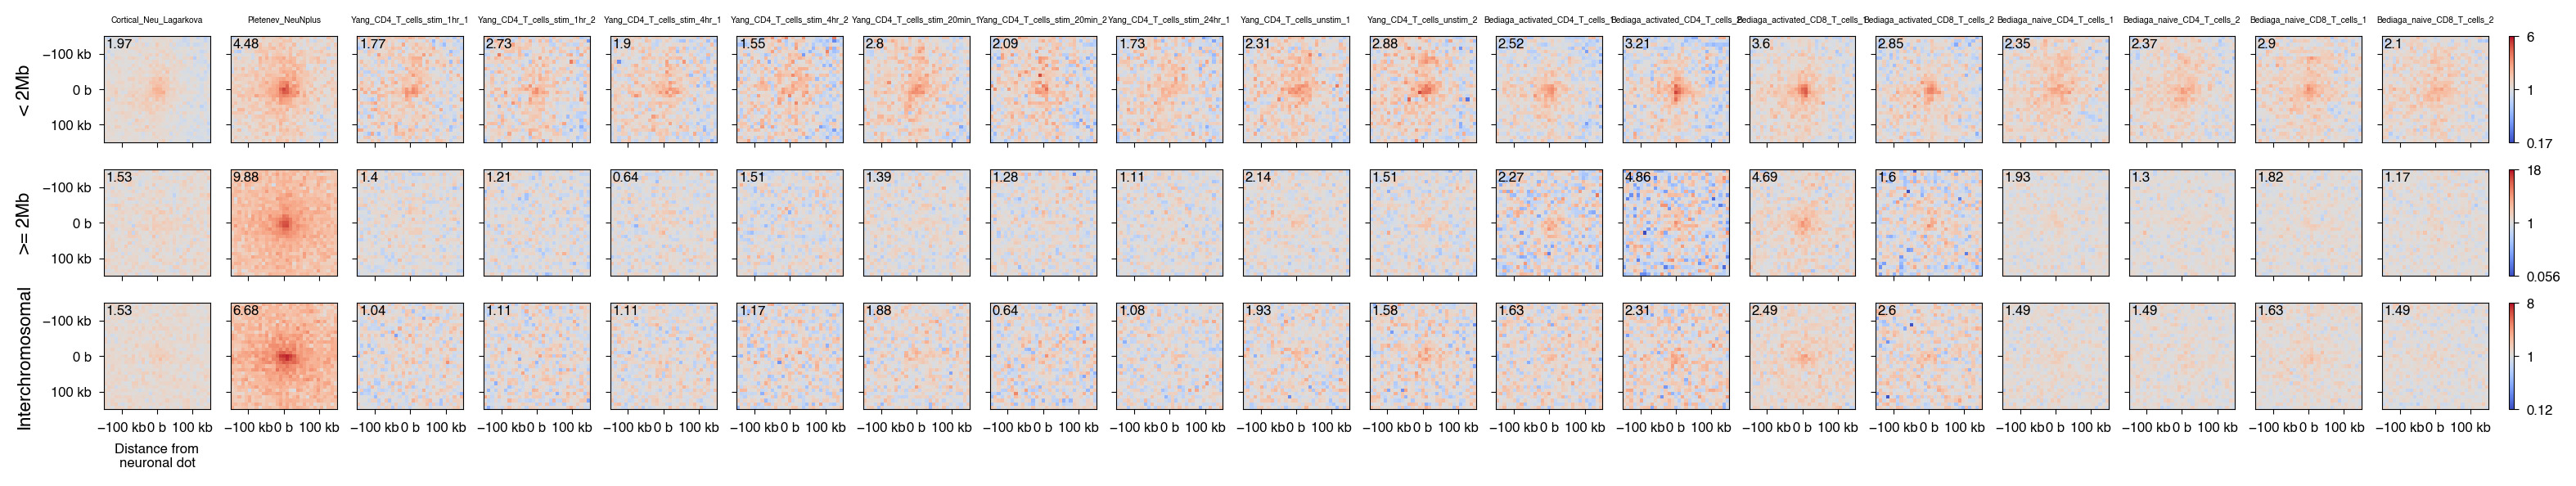

In [23]:
# Plot data for each ct separately
from matplotlib.colors import LogNorm
from coolpuppy.lib.numutils import get_enrichment
from matplotlib import ticker
from matplotlib.ticker import EngFormatter
bp_formatter = EngFormatter('b')

# Method 1: Modifying individual parameters

# plt.rcParams['axes.labelsize'] = 14      # Font size for x and y labels
# plt.rcParams['xtick.labelsize'] = 12    # Font size for x-axis tick labels
# plt.rcParams['ytick.labelsize'] = 12    # Font size for y-axis tick labels
# plt.rcParams['legend.fontsize'] = 10     # Font size for legend entries
# plt.rcParams['font.size'] = 12          # General font size for all text elements


def format_ticks(ax, x=True, y=True, rotate=True):
    if y:
        ax.yaxis.set_major_formatter(bp_formatter)
        ax.yaxis.set_major_locator(ticker.MultipleLocator(1e5))
    if x:
        ax.xaxis.set_major_formatter(bp_formatter)
        ax.xaxis.set_major_locator(ticker.MultipleLocator(1e5))
        ax.xaxis.tick_bottom()
        
        
nrows, ncols = 3, len(cts)
wr = [1]*ncols
wr.append(0.05)
fig, axs = plt.subplots(nrows, ncols+1, dpi=200, figsize=(ncols, nrows),
                        gridspec_kw={'width_ratios': wr})

vmax = {'short': 6, 'long': 18, 'trans': 8}
vmin = {k: 1/val for k, val in vmax.items()}
pup_grps = ['short', 'long', 'trans']

for i, pup in enumerate(pup_grps):
    for j, ct in enumerate(cts):
        arr = pup_hand[ct][pup]['data'][0]
        im = axs[i, j].imshow(
            arr, 
            cmap='coolwarm',
            norm=LogNorm(vmax=vmax[pup], vmin=vmin[pup]),
            extent=(-150000, 150000, 150000, -150000)
        )
        
        # Enrichment
        en = get_enrichment(arr, 0)
        axs[i, j].text(0.02, 0.98, round(en, 2), va='top', 
                       transform=axs[i, j].transAxes, fontsize=6)
        
        format_ticks(axs[i, j])
    
    # Colorbar
    plt.colorbar(im, cax=axs[i, ncols], ticks=[vmin[pup], 1, vmax[pup]], 
                 format=ticker.FuncFormatter(lambda x, pos: f"{x:.2g}"))
    axs[i, ncols].set_box_aspect(20)
    axs[i, ncols].minorticks_off()

# Ticks
for i in range(3):
    for j in range(1, ncols):
        axs[i, j].yaxis.set_ticklabels([])

# for i, j in [[0, 0], [0, 1], [1, 0], [1, 1]]:
#     axs[i, j].xaxis.set_ticklabels([])

for i in range(nrows-1):
    for j in range(ncols):
       axs[i, j].xaxis.set_ticklabels([]) 
    
# Labels
for i, ct in enumerate(cts):
    axs[0, i].set_title(ct, size=3.7)
# axs[0, 1].set_title(cts[1])
axs[0, 0].set_ylabel('< 2Mb', size=8)
axs[1, 0].set_ylabel('>= 2Mb', size=8)
axs[2, 0].set_ylabel('Interchromosomal', size=8)

axs[2, 0].set_xlabel('Distance from\nneuronal dot', size=6)
# axs[2, 1].set_xlabel('Distance from\nH3K27me3 peak')

# plt.tight_layout()

# plt.savefig('coolpup.hand.our_and_Hu2021_merged.pdf', bbox_inches='tight')
# plt.savefig('coolpup.hand.our.pdf', bbox_inches='tight')
# plt.savefig('coolpup.hand.Hu2021.pdf', bbox_inches='tight')
# plt.savefig('coolpup.hand.Tian2023.EN_IN.MTG.pdf', bbox_inches='tight')
# plt.savefig('coolpup.hand.iPSC_Lu_Choi_Rahman.pdf', bbox_inches='tight')